# Saint-Ouen en mutation : recompositions socio-spatiales et dynamiques urbaines depuis les années 2010

*Projet Python pour la data science — Borhane Yahiaoui et Pauline Aurignac - 2026*

## Sommaire

- Introduction
- I - Création et exploration des jeux de données principaux
  - A - Données géographiques
  - B - Données immobilières
    - 1 - Import et nettoyage
    - 2 - Jointure
    - 3 - Création d'un jeu de données figé et nettoyé
  - C - Données Filosofi
  - D - Données couples famille-ménages
  - E - Données activités résidents
- II - Évolution démographique : qui vit à Saint-Ouen ?
- III - Transformations socio-économiques : le profil des quartiers se modifie-t-il ?
  - A - Un niveau de vie clairement en hausse
  - B - Mixité sociale et part des cadres à Saint-Ouen : une transformation inégale selon les quartiers
  - C - Une structure des ménages qui évolue
- IV - Logements et transactions : comment évolue le cadre résidentiel ?
- Conclusion

## Introduction

Commune limitrophe du nord de Paris en Seine-Saint-Denis, Saint-Ouen-sur-Seine a connu au cours des quinze dernières années une profonde transformation socio-économique. Longtemps associée à un passé industriel marqué par une forte présence ouvrière et une réputation de ville populaire en difficulté, elle s’impose aujourd’hui comme un pôle d’attractivité majeur de la première couronne parisienne. Portée par d’importants projets d’aménagement urbain, l’implantation de sièges sociaux et l’extension de la ligne 14 du métro, la commune attire désormais une population plus aisée et suscite un fort intérêt immobilier, au point d’incarner aux yeux de beaucoup un symbole de réhabilitation urbaine.
L’objectif de ce travail est d’examiner empiriquement à l’aide de Python plusieurs dimensions clés de l’évolution de Saint-Ouen depuis les années 2010. Nous étudions ainsi conjointement la dynamique démographique, l’évolution de la structure socio-économique, les transformations du parc de logements et du marché immobilier, ainsi que l’hétérogénéité des trajectoires entre les différents quartiers de la commune.

*Problématique : Dans quelle mesure les transformations récentes de Saint-Ouen s’accompagnent-elles d’une recomposition socio-spatiale, et comment celle-ci se différencie-t-elle selon les quartiers ?*

Pour y répondre, cette étude couvre la période allant du début des années 2010 aux données les plus récentes disponibles (notamment via le recensement de l’INSEE et les bases de transactions immobilières DVF). Nous étudions les évolutions à l’échelle de la commune et des quartiers, à l’aide du découpage infra-communal des IRIS (Îlots Regroupés pour l’Information Statistique).
Nous présentons dans un premier temps les sources mobilisées et les choix méthodologiques retenus pour harmoniser ces données dans le temps et dans l’espace. Nous analysons ensuite successivement les évolutions démographiques, socio-économiques et résidentielles de la commune, avant de croiser ces différentes dimensions afin de mettre en lumière les dynamiques communes et les contrastes persistants entre quartiers.

Cette approche se veut résolument descriptive : elle vise à mesurer et caractériser des évolutions ainsi que des corrélations spatiales et temporelles observées dans les données publiques, sans prétendre identifier à elle seule les mécanismes causaux à l’œuvre ni démontrer directement des phénomènes d’éviction résidentielle.


In [1]:
%pip install -r requirements.txt


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
from matplotlib.ticker import StrMethodFormatter, FuncFormatter
from pathlib import Path
import pyarrow.parquet as pq
import utils
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "DejaVu Sans", "Arial"]

%config InlineBackend.figure_format = 'retina'

## I - Création et exploration des jeux de données principaux

### A - Données géographiques

IRIS signifie « Ilots Regroupés pour l’Information Statistique ». L’Insee a créé ce découpage pour diffuser des statistiques à une échelle plus fine que celle de la commune. Un IRIS regroupe généralement autour de 2 000 habitants, mais sa taille peut varier. Ces unités permettent ici de comparer les quartiers de Saint-Ouen-sur-Seine.

Le « périmètre d’étude » désigne l’espace géographique retenu pour l’analyse : ici, les IRIS de la commune de Saint-Ouen-sur-Seine (code INSEE 93070). `zone_etude` est le GeoDataFrame qui contient les polygones de ces IRIS ; il sert à joindre les ventes aux quartiers et à cartographier les résultats. Ce périmètre n’est ni une zone tampon autour d’un transport ni une sélection de gares. La ligne 14 dispose d’un chargeur séparé dans `utils.py`, mais elle n’est pas utilisée dans l’analyse présentée ici.

In [3]:
gdf_iris = gpd.read_file("data/raw/IDF_iris.geojson")
zone_etude = utils.charger_zone_etude(code_insee="93070")

### B - Données immobilières

#### 1 - Import et nettoyage

Les données choisies pour observer les mutations immobilières sont les **données de valeurs foncières (DVF)**, dont la disponibilité est garantie par le décret n° 2018‑1350 du 28 décembre 2018 sur les cinq dernières anénes, avec des informations comme la date, la nature de la mutation, le type de local, sa valeur foncière, sa surface et ses coordonnées géographiques. Des données plus anciennes sont disponibles dans la rubrique "Ressources communautaires" de la page "Données de valeurs foncières" sur le site data.gouv.fr. Ces données ne sont pas fournies par les ministères économiques et financiers comme les données des 5 dernières années, mais elles n'étaient pas disponibles ailleurs pour des dates antérieures à 2021. Ainsi, les données de 2021 à 2026 mises à disposition sur data.gouv.fr ont été téléchargées au format .csv, et les données antérieures (de 2018 à 2020) au format .parquet. Les fichiers .parquet sont des fichiers nationaux tandis que les .csv sont limités à Saint-Ouen.

Remarque : aucune API gratuite n'est mise à disposition sur le site data.gouv.fr pour avoir accès aux données DVF. 

Le tableau ci-dessous montre quelques lignes des données de 2021 (fichier .csv) et de 2018 (fichier.parquet) tels qu’ils ont été fournis : 

In [4]:
fichier_csv = Path("data/raw/93070.2021.csv")
fichier_parquet = Path("data/raw/dvf-2018.parquet")

df_csv = pd.read_csv(fichier_csv, nrows=5)

parquet = pq.ParquetFile(fichier_parquet)
df_parquet = next(parquet.iter_batches(batch_size=5)).to_pandas()

Pour travailler sur ces données on commence par les charger :

In [5]:
df_dvf_brut = utils.charger_dvf(
    code_insee=93070,
    dossier=None,
)

✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/dvf-2018.parquet : 2296 lignes pour 2018
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/dvf-2019.parquet : 3140 lignes pour 2019
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/dvf-2020.parquet : 2540 lignes pour 2020
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2021.csv : 3462 lignes pour 2021
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2022.csv : 3019 lignes pour 2022
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2023.csv : 2404 lignes pour 2023
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2024.csv : 2471 lignes pour 2024
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2025.csv : 2650 lignes pour 2025


Le helper `_aggreger_dvf_par_mutation`, appelé par `nettoyer_dvf`, transforme les lignes DVF en une observation par `id_mutation`. Il supprime d’abord les lignes strictement identiques, normalise les identifiants de mutation et écarte ceux qui sont absents. Pour chaque mutation, il :

- ne conserve que les ventes ou ventes en l’état futur d’achèvement comportant au moins un appartement ou une maison ;
- conserve une seule valeur foncière si une valeur non manquante unique est identifiable ; les mutations sans valeur exploitable ou avec plusieurs valeurs contradictoires sont écartées ;
- additionne les surfaces des seuls appartements et maisons ; une surface résidentielle manquante ou non positive entraîne l’exclusion de la mutation ;
- écarte les mutations dont la surface résidentielle totale est inférieure ou égale à 10 m² ou dont la valeur foncière est inférieure ou égale à 10 000 € ;
- calcule un prix au m² en divisant la valeur foncière de la mutation par la surface résidentielle totale, puis conserve les prix compris entre 2 000 et 15 000 €/m² ;
- exige une année cohérente et au moins une coordonnée résidentielle valide dans l’emprise géographique définie par le code.

Les seuils sont des choix de nettoyage : ils visent à écarter des observations peu plausibles pour notre analyse résidentielle, mais peuvent aussi exclure certaines transactions réelles. Nous les documentons et interprétons les résultats en conséquence.

Le prix au m² obtenu est un indicateur approximatif du prix résidentiel : la valeur foncière est celle de la mutation et peut inclure une dépendance vendue avec le logement. Les données DVF ne contiennent pas le code IRIS. Celui-ci est ajouté après ce nettoyage, par jointure spatiale entre les coordonnées des mutations et les polygones IRIS.

In [6]:
df_logements_nettoye = utils.nettoyer_dvf(df_dvf_brut)

Agrégation DVF : 1647 lignes strictement identiques supprimées ; 13 mutations exclues pour valeur foncière absente/contradictoire ; 0 pour nature absente/contradictoire ; 0 pour surface résidentielle manquante/invalide ; 84 sans coordonnée résidentielle valide ; 0 avec années contradictoires ; 0 avec dates contradictoires.
Filtre DVF terminé : 6140 mutations retenues sur 21982 lignes chargées.


#### 2 - Jointure 

Les fichiers DVF ne donnent pas directement le code IRIS de chaque mutation. Pour le construire, la fonction `joindre_ventes_aux_iris` du fichier utils exige des coordonnées `longitude` et `latitude` ainsi que le prix calculé `prix_m2`. Elle retire les observations sans coordonnées, crée un point pour chaque mutation en EPSG:4326, puis reprojette ces points dans le système de coordonnées des polygones IRIS si nécessaire.

La jointure spatiale utilise `predicate="within"` : un point est rattaché à l'IRIS dont le polygone le contient strictement. `how="left"` conserve toutes les mutations avec coordonnées; si aucune géométrie ne les contient, leur code IRIS reste manquant. Un point situé exactement sur la frontière d'un IRIS n'est pas considéré comme `within` et peut donc ne pas être rattaché. Ces cas sont conservés dans le tableau de jointure, mais exclus de l'agrégation par IRIS.

`agreger_dvf_par_iris` calcule ensuite, pour chaque IRIS, la médiane de `prix_m2` et le nombre d'observations. Comme le chargeur fournit désormais une ligne par `id_mutation`, `nb_ventes` compte ici les mutations retenues et rattachées, non les lots DVF d'origine. Le prix au m² reste un proxy : il divise la valeur totale de la mutation par la surface résidentielle totale et peut donc inclure la valeur d'une dépendance ou d'un autre bien vendu avec le logement.

In [7]:
ventes_avec_iris = utils.joindre_ventes_aux_iris(
    df_logements_nettoye,
    zone_etude,
)

df_logements_final = pd.DataFrame(
    ventes_avec_iris.drop(columns="geometry")
)

#### 3 - Création d’un jeu de données figé et nettoyé

Après le nettoyage des données DVF et leur jointure spatiale avec les polygones IRIS, nous enregistrons le tableau consolidé dans `data/processed/data_immo.parquet`. Il contient une ligne par mutation, les variables DVF retenues et le code IRIS correspondant. Les mutations qui n’ont pas pu être associées à un IRIS sont conservées, avec un code manquant. Nous pourrons ainsi réutiliser ces données dans la suite du notebook sans recharger les fichiers bruts ni refaire le nettoyage et la jointure.

In [8]:
chemin_parquet_immo = utils.creer_data_immo_parquet(df_logements_final)
df_logements = pd.read_parquet(chemin_parquet_immo)

Parquet créé : /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/processed/data_immo.parquet (6140 lignes, années [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]).


### C - Données Filosofi

On charge maintenant les fichiers Filosofi (Fichier Localisé Social et Fiscal) de 2018 et de 2021 et les prépare à l’échelle des IRIS de Saint-Ouen. Les données Filosofi de l'Insee mesurent les revenus des ménages, les inégalités et la pauvreté à tous les niveaux géographiques (du national jusqu'au quartier). Les résultats sont stockés dans `st_ouen_2018` et `st_ouen_2021`. Les variables `col_niv_2018` et `col_niv_2021` indiquent le nom de la colonne de niveau de vie retenue pour chaque millésime.

Ces objets permettront de comparer les indicateurs de niveau de vie entre les IRIS et entre les deux années.

In [9]:
st_ouen_iris = utils.charger_iris_api("93070")

st_ouen_2018, col_niv_2018 = utils.charger_et_preparer_filosofi(
    2018, "data/raw/BASE_TD_FILO_DISP_IRIS_2018.xlsx", st_ouen_iris
)
st_ouen_2021, col_niv_2021 = utils.charger_et_preparer_filosofi(
    2021, "data/raw/BASE_TD_FILO_IRIS_2021_DISP.xlsx", st_ouen_iris
)

⚠️ API WFS IGN injoignable, bascule sur un fichier local...
-> Contours IRIS chargés depuis le fichier local IDF_iris.geojson.


### D - Données couples famille-ménages

On charge maintenant les bases infra-communales de l'Insee sur les couples, familles et ménages pour 2011 et 2022 (base-ic-couples-familles-menages-2011.xls et base-ic-couples-familles-menages-2022.xlsx). Ces fichiers décrivent, pour chaque IRIS, la structure des ménages : nombre de ménages, ménages d'une personne, couples sans enfant, couples avec enfants, familles monoparentales, etc. Ils permettront de caractériser l'évolution du profil des ménages de Saint-Ouen, en complément des indicateurs socioprofessionnels.

La cellule lit chaque fichier Excel stocké dans data/raw avec pd.read_excel. L'argument skiprows=5 saute les 5 premières lignes, qui contiennent des informations de présentation (titre, source) et non les données, de sorte que la ligne suivante devient l'en-tête des colonnes.

Les résultats sont stockés dans deux DataFrames, df_2011_menages et df_2022_menages. Le suffixe _menages les distingue des tables df_2011 et df_2022 construites à partir des données d'activité.

À ce stade, ces tables couvrent tous les IRIS de la source et pas seulement Saint-Ouen. Les effectifs sont des nombres de ménages, et non des taux. Le préfixe des colonnes change selon l'année (P11_ pour 2011, P22_ pour 2022), ce qu'il faudra prendre en compte au moment de comparer les deux millésimes.

In [10]:
df_2011_menages = pd.read_excel(
    Path("data/raw/base-ic-couples-familles-menages-2011.xls"), skiprows=5
)
df_2022_menages = pd.read_excel(
    Path("data/raw/base-ic-couples-familles-menages-2022.xlsx"), skiprows=5
)

/var/folders/0w/czcrdq993f90fd70tsy9vw580000gn/T/ipykernel_97066/1914928878.py:4: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  df_2022_menages = pd.read_excel(


On calcule maintenant deux indicateurs de **structure des ménages** pour chaque IRIS, aux deux dates, puis leur évolution entre 2011 et 2022. Les deux proviennent de la même source, les bases Insee couples, familles et ménages :
- la **part des ménages d'une personne et des couples sans enfant** parmi l'ensemble des ménages de l'IRIS ;
- la **part des familles monoparentales et des familles nombreuses** parmi l'ensemble des ménages de l'IRIS.

**Étape 1 : nettoyage des tables**

La fonction `preparer_csp` est appliquée à `df_2011_menages` et `df_2022_menages` :
- le code IRIS est normalisé sur 9 caractères ;
- toutes les autres colonnes sont converties en valeurs numériques ;
- les valeurs non convertibles deviennent des valeurs manquantes, sans être remplacées par une estimation.

**Étape 2 : calcul des indicateurs par année**

Deux fonctions sont appliquées à chaque millésime. Le préfixe des colonnes change selon l'année (`C11` pour 2011, `C22` pour 2022), c'est pourquoi il est passé en argument.

- `calcul_part_menages_cibles` additionne, pour chaque IRIS, les ménages d'une personne et les couples sans enfant (`nb_cible`), puis divise cette somme par le nombre total de ménages pour obtenir la part en pourcentage (`part_cible_pct`). Les résultats sont stockés dans `ind_2011` et `ind_2022`.
- `calcul_part_familles_cibles` fait le même calcul pour les familles monoparentales et les familles nombreuses (trois enfants ou plus). Les résultats sont stockés dans `fam_2011` et `fam_2022`.

Quelques choix de nettoyage communs aux deux fonctions :
- un IRIS sans ménage donne une valeur manquante, pour éviter une division par zéro ;
- les valeurs manquantes des effectifs sont traitées comme des zéros dans la somme ;
- si l'une des colonnes indispensables est absente du fichier, la fonction s'arrête avec une erreur explicite.

**Étape 3 : évolution entre les deux dates**

La fonction `calculer_evolution` est appliquée à chacun des deux indicateurs. Elle part des IRIS de Saint-Ouen (code et géométrie) et y joint successivement les indicateurs de 2011 et de 2022 avec une **jointure à gauche**. Tous les IRIS de la commune sont donc conservés, et ceux qui manquent à l'une des dates gardent une valeur manquante, ce qui les rendra visibles sur les cartes. Les colonnes sont suffixées par l'année (`nb_2011`, `part_2011`, `nb_2022`, `part_2022`).

L'évolution est ensuite calculée en **points de pourcentage** : `evol_pts = part_2022 - part_2011`. Une différence en points est préférable à une variation relative, qui serait instable lorsque la part de départ est faible.

**Résultat**

On obtient deux tables, chacune avec une ligne par IRIS de Saint-Ouen, sa géométrie, les effectifs et les parts des deux années, et leur évolution :
- `evol_menages` pour les ménages d'une personne et les couples sans enfant ;
- `evol_familles` pour les familles monoparentales et nombreuses.

Elles peuvent être cartographiées directement.

**Point d'attention**

Chacun de ces indicateurs regroupe deux types de ménages ou de familles. Une hausse de la part peut venir de l'une des deux composantes, ou des deux. Il faudra donc rester prudent dans l'interprétation, et regarder les composantes séparément si nécessaire.

In [11]:
ind_2011 = utils.calcul_part_menages_cibles(utils.preparer_csp(df_2011_menages), "C11")
ind_2022 = utils.calcul_part_menages_cibles(utils.preparer_csp(df_2022_menages), "C22")

fam_2011 = utils.calcul_part_familles_cibles(utils.preparer_csp(df_2011_menages), "C11")
fam_2022 = utils.calcul_part_familles_cibles(utils.preparer_csp(df_2022_menages), "C22")

evol_menages= utils.calculer_evolution(st_ouen_iris, ind_2011, ind_2022, 2011, 2022)
evol_familles = utils.calculer_evolution(st_ouen_iris, fam_2011, fam_2022, 2011, 2022)

### E - Données activités résidents


On charge maintenant les bases infra-communales de l'Insee sur l'activité des résidents pour les millésimes 2011 et 2022 (`base-ic-activite-residents-2011.xls` et `base-ic-activite-residents-2022.xlsx`). Ces fichiers décrivent la population active à l'échelle des IRIS (emploi, chômage, statut des actifs, etc.). 

Concrètement, on :
1. Définit les chemins des deux fichiers, stockés dans `data/raw/`.
2. Lit chaque fichier Excel avec `pd.read_excel`. L'argument `skiprows=5` saute les 5 premières lignes, qui contiennent des informations de présentation (titre, source, etc.) et non les données. La ligne suivante est ainsi utilisée comme en-tête des colonnes.
3. Stocke les résultats dans deux DataFrames, `df_2011_1` et `df_2022_1`, qui couvrent encore tous les IRIS de la source et pas seulement Saint-Ouen.

In [12]:
df_2011_act = pd.read_excel(
    Path("data/raw/base-ic-activite-residents-2011.xls"), skiprows=5
)
df_2022_act = pd.read_excel(
    Path("data/raw/base-ic-activite-residents-2022.xlsx"), skiprows=5
)

/var/folders/0w/czcrdq993f90fd70tsy9vw580000gn/T/ipykernel_97066/1056140763.py:4: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  df_2022_act = pd.read_excel(


Les deux tables Insee (2011 et 2022) sont traitées par deux fonctions de `utils.py`, appliquées de la même manière aux deux millésimes pour que les résultats soient comparables.

Nettoyage (`preparer_csp`) :
- Harmonisation du code IRIS : l'identifiant est converti en texte, débarrassé d'un éventuel suffixe `.0` et des espaces, puis complété par des zéros à gauche pour atteindre 9 caractères. Cela évite les échecs de jointure dus à des formats différents (entier, flottant, zéro initial perdu), notamment avec les autres sources du projet (Filosofi, géométries IRIS).
- Conversion numérique : toutes les autres colonnes sont converties avec `errors="coerce"`. Les valeurs non numériques (cellules vides, symboles de secret statistique, texte) deviennent des valeurs manquantes (`NaN`) au lieu de bloquer le traitement. Nous faisons le choix de ne pas imputer ces valeurs : un IRIS non renseigné reste manquant dans les calculs et les cartes.

Construction des indicateurs (`calcul_indicateurs`) :
- Détection des colonnes par motifs : le nom des variables dépend du millésime (préfixe `C11` ou `C22`, codes `CS` ou `GSEC`). Les colonnes sont donc repérées par leur nom plutôt que codées en dur, et la fonction s'arrête avec une erreur explicite si elles sont introuvables, afin d'éviter un calcul silencieusement faux.
- Part des cadres : effectif de cadres et professions intellectuelles supérieures rapporté à l'ensemble des actifs de 15 à 64 ans, en pourcentage. Un dénominateur nul donne une valeur manquante plutôt qu'une division par zéro.
- Mixité sociale : indice de Shannon calculé sur la répartition des six groupes socioprofessionnels des actifs de 15 à 64 ans. Il est d'autant plus élevé que les groupes sont nombreux et équilibrés dans l'IRIS, et nul si un seul groupe domine totalement. Les groupes d'effectif nul sont exclus du calcul, et l'indice n'est pas défini s'il y a moins de deux groupes.

Ces choix permettent de comparer l'évolution de la composition sociale des IRIS de Saint-Ouen entre 2011 et 2022.

In [13]:
df_2011_csp = utils.calcul_indicateurs(utils.preparer_csp(df_2011_act), "2011")
df_2022_csp = utils.calcul_indicateurs(utils.preparer_csp(df_2022_act), "2022")

On restreint maintenant les données Insee sur l'activité des résidents à la commune de Saint-Ouen-sur-Seine, et on leur associe la géométrie des IRIS pour pouvoir les cartographier.

La cellule joint `st_ouen_iris` (les IRIS de Saint-Ouen, avec leurs contours) à chacune des deux tables nationales `df_2011` et `df_2022` (qui contiennent les indicateurs `part_cadres` et `mixité_sociale`), à partir du code IRIS.

- Jointure interne (`how="inner"`) : seuls les IRIS présents dans les deux tables sont conservés. Cela filtre les données sur Saint-Ouen, puisque `st_ouen_iris` ne contient que les IRIS de la commune, et écarte tous les autres IRIS des tables Insee.
- Clé commune : le code IRIS a été normalisé sur 9 caractères en amont (`preparer_csp` et chargement des géométries), ce qui garantit que les identifiants correspondent.
- Type du résultat : `st_ouen_iris` étant un GeoDataFrame et placé à gauche de la jointure, les résultats `st_ouen_2011_csp` et `st_ouen_2022_csp` en sont aussi, et peuvent être tracés directement.

Chaque table contient une ligne par IRIS de Saint-Ouen, avec sa géométrie et ses indicateurs pour l'année considérée.

La jointure interne peut faire perdre des IRIS si le découpage a changé entre 2011 et 2022 ou si un IRIS est absent du fichier Insee. Il faut donc comparer le nombre de lignes obtenu au nombre d'IRIS de `st_ouen_iris`.

In [14]:
st_ouen_2011_csp = st_ouen_iris.merge(df_2011_csp, on=utils.COL_IRIS, how="inner")
st_ouen_2022_csp = st_ouen_iris.merge(df_2022_csp, on=utils.COL_IRIS, how="inner")

Enfin, on construit la table d'évolution (`evol`):
- On joint, sur le code IRIS, les indicateurs de 2011 (avec la géométrie) et ceux de 2022. Le suffixe `_2011` ou `_2022` distingue les colonnes de même nom. La jointure est interne : seuls les IRIS présents aux deux dates sont conservés, ce qui garantit une comparaison sur un périmètre identique.
- On calcule ensuite les écarts entre 2022 et 2011 :
  - `d_cadres` : variation de la part des cadres, en **points de pourcentage** (et non en variation relative, instable quand la part de départ est faible) ;
  - `d_mixite` : variation de l'indice de Shannon.

In [15]:
evol = st_ouen_2011_csp[[utils.COL_IRIS, "geometry", "part_cadres", "mixité_sociale"]].merge(
    st_ouen_2022_csp[[utils.COL_IRIS, "part_cadres", "mixité_sociale"]],
    on=utils.COL_IRIS,
    suffixes=("_2011", "_2022"),
)
evol["d_cadres"] = evol["part_cadres_2022"] - evol["part_cadres_2011"]
evol["d_mixite"] = evol["mixité_sociale_2022"] - evol["mixité_sociale_2011"]

## II - Évolution démographique : qui vit à Saint-Ouen ?

Pour commencer, il est intéressant de se demander quel est le profil démographique de la ville de Saint-Ouen. On interroge alors l'API Melodi de l'INSEE pour importer les données démographiques de Saint-Ouen et étudier les évolutions entre 

In [16]:
population_commune = utils.charger_population_commune(code_insee="93070")
pyramide_population = utils.preparer_pyramide_ages(
    population_commune,
    annee=[2012, 2023],
)

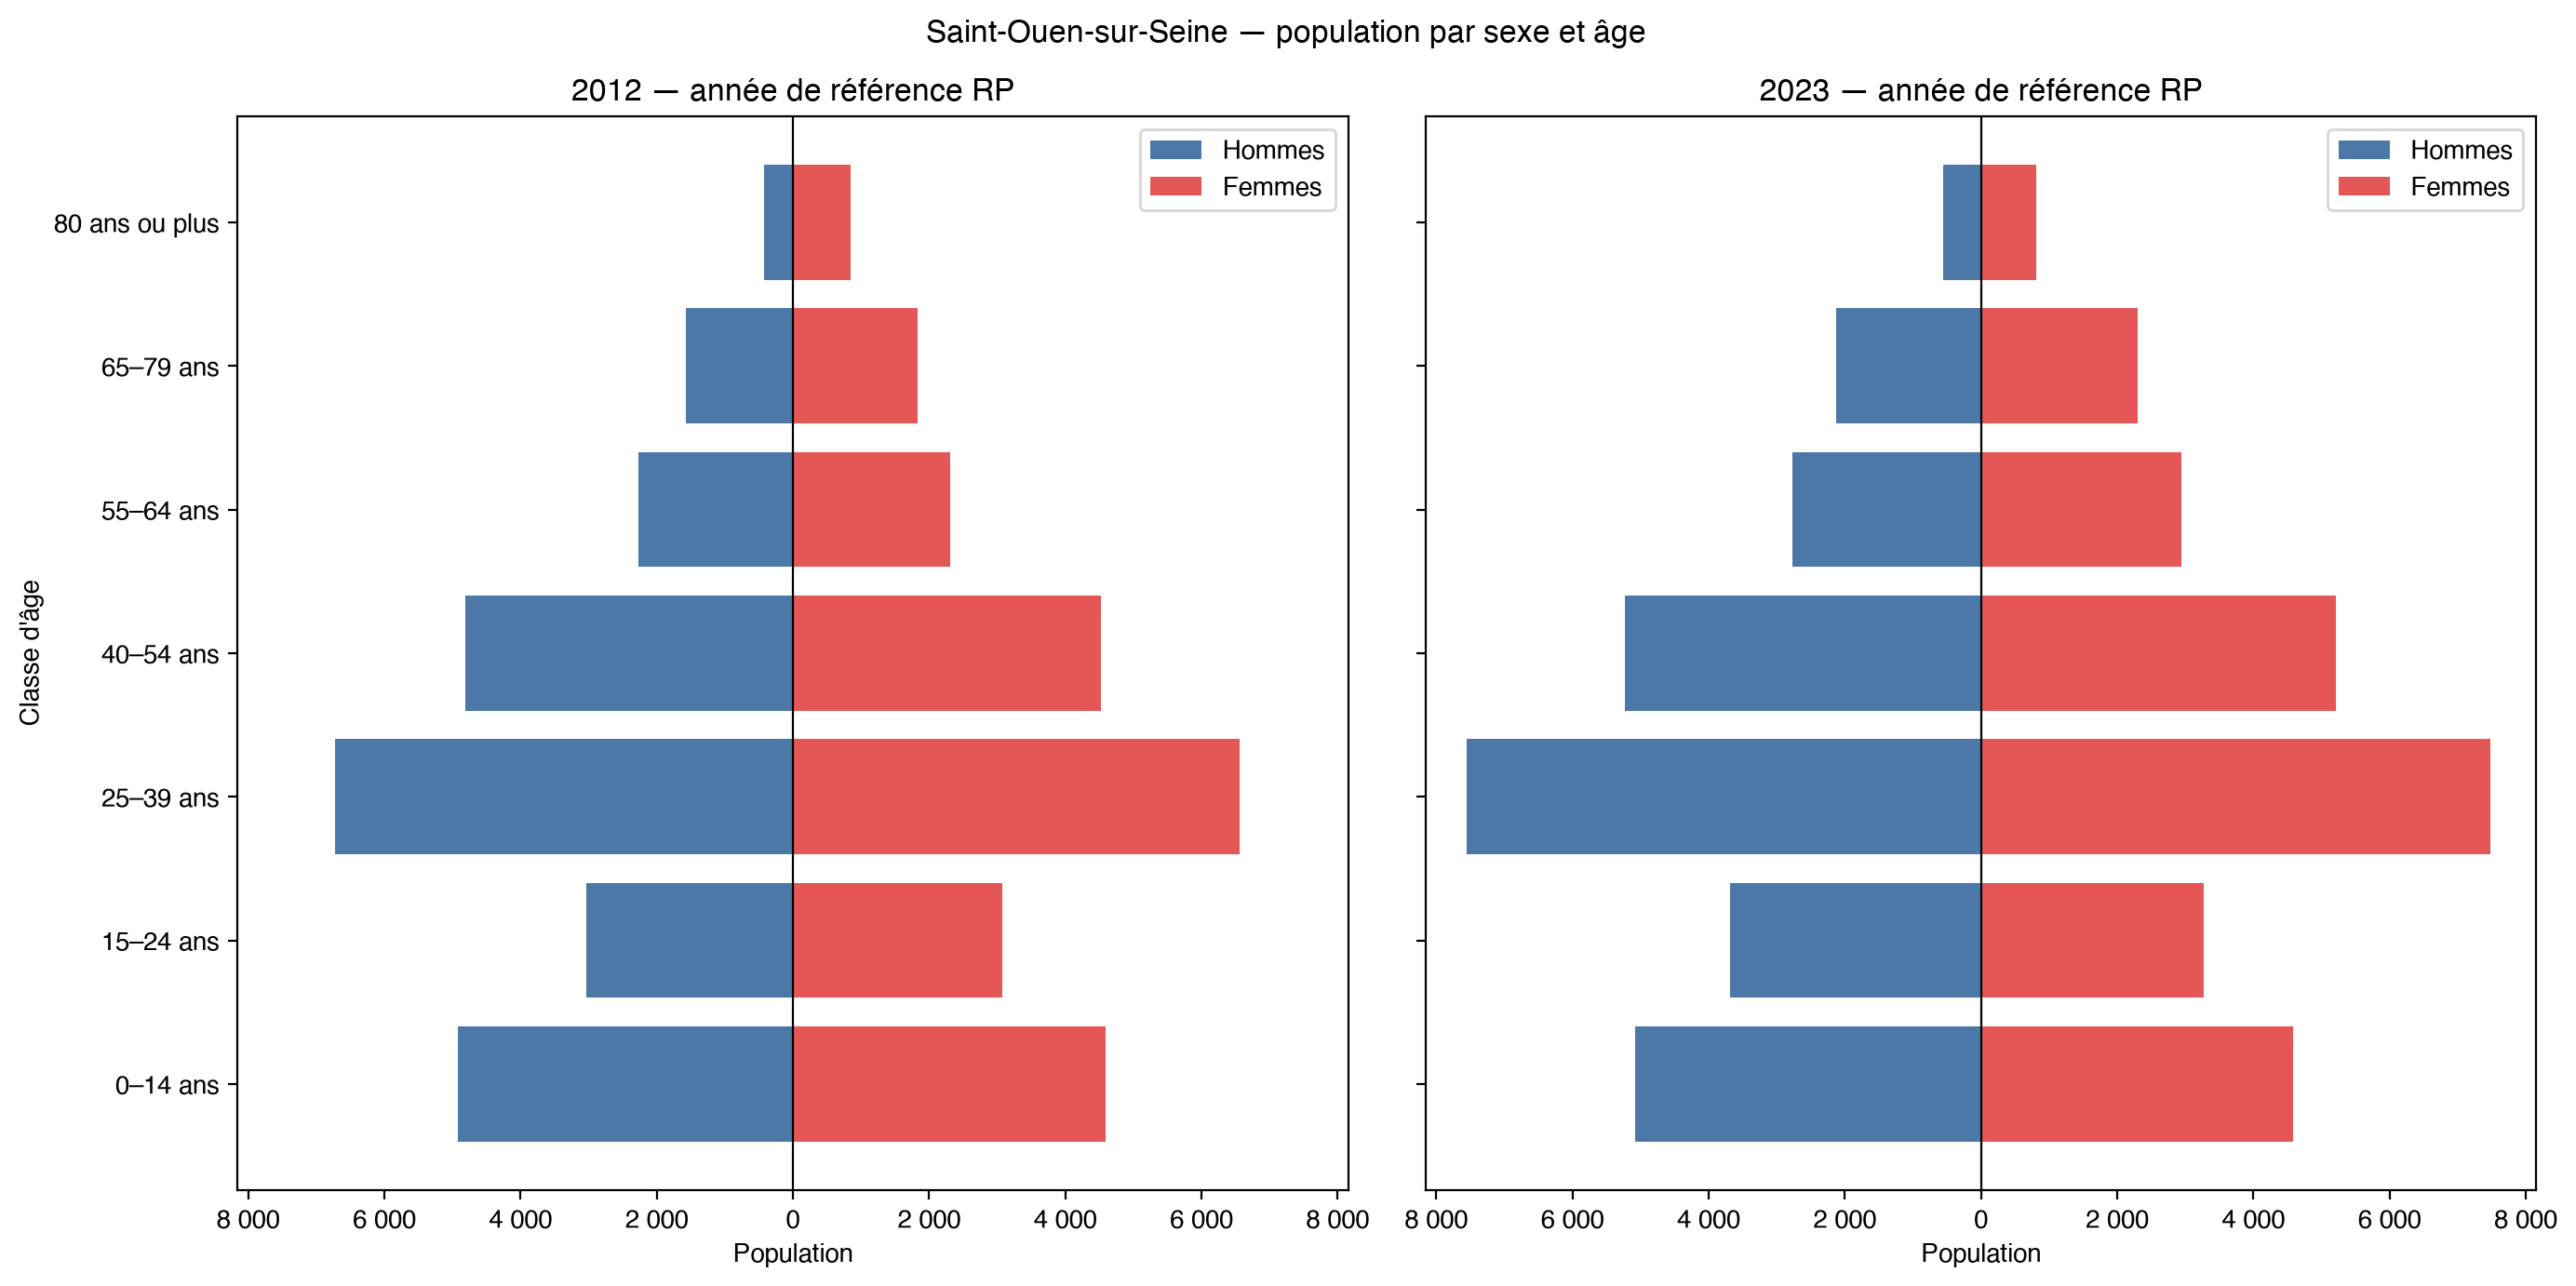

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

maximum = pyramide_population[["femmes", "hommes"]].to_numpy().max() * 1.08

for ax, annee in zip(axes, sorted(pyramide_population["annee"].unique())):
    donnees_annee = pyramide_population.loc[
        pyramide_population["annee"] == annee
    ]

    ax.barh(
        donnees_annee["classe_age"],
        -donnees_annee["hommes"],
        color="#4C78A8",
        label="Hommes",
    )
    ax.barh(
        donnees_annee["classe_age"],
        donnees_annee["femmes"],
        color="#E45756",
        label="Femmes",
    )

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-maximum, maximum)
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda valeur, _: f"{abs(valeur):,.0f}".replace(",", " "))
    )
    ax.set_title(f"{annee} — année de référence RP")
    ax.set_xlabel("Population")
    ax.legend()

axes[0].set_ylabel("Classe d'âge")
fig.suptitle("Saint-Ouen-sur-Seine — population par sexe et âge")
fig.tight_layout()
plt.show()

La comparaison des pyramides des âges de Saint-Ouen-sur-Seine entre 2012 et 2023 suggère une progression marquée des classes d’âge actif.


- On constate une structure « en toupie » dominée par les 25–54 ans aux deux dates. La population se concentre fortement dans les classes d’âge actif. Le pic se situe chez les 25–39 ans, qui passent d’environ 6 700 hommes et 6 550 femmes en 2012 à près de 7 500 hommes et 7 450 femmes en 2023 (soit près de 15 000 habitants dans cette seule tranche), suivis par les 40–54 ans (autour de 5 150 hommes et 5 200 femmes en 2023).
- On remarque en effet une croissance plus marquée chez les adultes d’âge actif. Entre 2012 et 2023, l’élargissement de la pyramide repose essentiellement sur la progression des 25–39 ans (+800 à +900 personnes par sexe), des 40–54 ans (+350 à +700) et des 55–64 ans (+500 à +650). À l’inverse, la base des 0–14 ans reste quasi stable (environ 5 000 garçons et 4 600 filles), et le creux des 15–24 ans (3 650 hommes et 3 300 femmes en 2023) demeure prononcé.
- Enfin, on observe un vieillissement contenu et un déséquilibre hommes-femmes aux grands âges. Les 65–79 ans progressent modérément (d’environ 1 600–1 800 par sexe en 2012 à 2 100–2 350 en 2023), tandis que le sommet des 80 ans ou plus reste étroit (environ 500 hommes et 850 à 900 femmes). La répartition par sexe est globalement équilibrée jusqu’à 54 ans, puis devient plus féminine à partir de 55 ans.


Cette progression des classes d’âge actif invite à examiner, dans la section suivante, l’évolution du profil socio-économique des quartiers.

## III - Transformations socio-économiques : le profil des quartiers se modifie-t-il ?
### A- Un niveau de vie clairement en hausse

Dans cette partie nous avons chercher à étudier l'évolution du niveau de vie médian des habitants de Saint-Ouen. 
Nous avons cherché à pouvoir utiliser une api pour ne pas avoir a stocker les données en local cependant le niveau le plus détaillé sur Melodi (API de l'INSEE) est le niveau communal. C'est donc inutilisable pour notre étude au niveau des quartiers IRIS.  

Nous comparons donc le niveau de vie médian 2018 et 2021 en s'appuyant sur des briques déjà factorisées dans utils.py. 

Pour ce faire, on fait la fusion des données géographiques et statistiques de 2018 et 2021 pour créer un unique jeu de données comparatif (st_ouen_evol). Il sélectionne d'abord les colonnes clés dans le DataFrame de 2021 (l'identifiant COL_IRIS et le niveau de vie médian col_niv_2021 qu'il renomme provisoirement en niv_2021), puis effectue une jointure interne sur l'identifiant unique de l'IRIS avec le DataFrame de 2018. Enfin, la colonne du niveau de vie de 2018 est renommée en niv_2018, ce qui permet d'associer pour chaque quartier de Saint-Ouen ses valeurs de revenus des deux années au sein d'une seule table prête pour le calcul de l'évolution.

In [18]:
st_ouen_evol = st_ouen_2018.merge(
    st_ouen_2021[[col_niv_2021, utils.COL_IRIS]].rename(columns={col_niv_2021: "niv_2021"}),
    on=utils.COL_IRIS,
    how="inner"
).rename(columns={col_niv_2018: "niv_2018"})

On veut donc construire une carte comparative qui vise à visualiser l'évolution du niveau de vie entre 2018 et 2021. 
On commence par préparer l'affichage de la carte. On calcule le taux d'évolution en pourcentage du niveau de vie médian entre 2018 et 2021 pour chaque IRIS. D'autre part, il normalise les échelles visuelles pour garantir une comparabilité rigoureuse sur les cartes : il détermine d'abord les bornes globales de revenus sur l'ensemble des deux années pour figer une échelle de couleurs commune aux cartes de niveaux de vie, puis il calcule la valeur absolue maximale d'évolution (max_abs_evol) afin de configurer une normalisation (mcolors.TwoSlopeNorm). Cette dernière permet de centrer précisément la palette de la carte d'évolution sur la valeur neutre de zéro (vcenter=0) avec une symétrie parfaite des deux côtés.

In [19]:
st_ouen_evol["evol_pct"] = (
    (st_ouen_evol["niv_2021"] - st_ouen_evol["niv_2018"])
    / st_ouen_evol["niv_2018"]
) * 100


vmin_niv = min(
    st_ouen_2018[col_niv_2018].min(), st_ouen_2021[col_niv_2021].min()
)
vmax_niv = max(
    st_ouen_2018[col_niv_2018].max(), st_ouen_2021[col_niv_2021].max()
)

max_abs_evol = max(
    abs(st_ouen_evol["evol_pct"].min()),
    abs(st_ouen_evol["evol_pct"].max()),
)
norm_evol = mcolors.TwoSlopeNorm(vmin=-max_abs_evol, vcenter=0, vmax=max_abs_evol)

/var/folders/0w/czcrdq993f90fd70tsy9vw580000gn/T/ipykernel_97066/1531851493.py:46: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  plt.tight_layout()
/Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.canvas.print_figure(bytes_io, **kw)


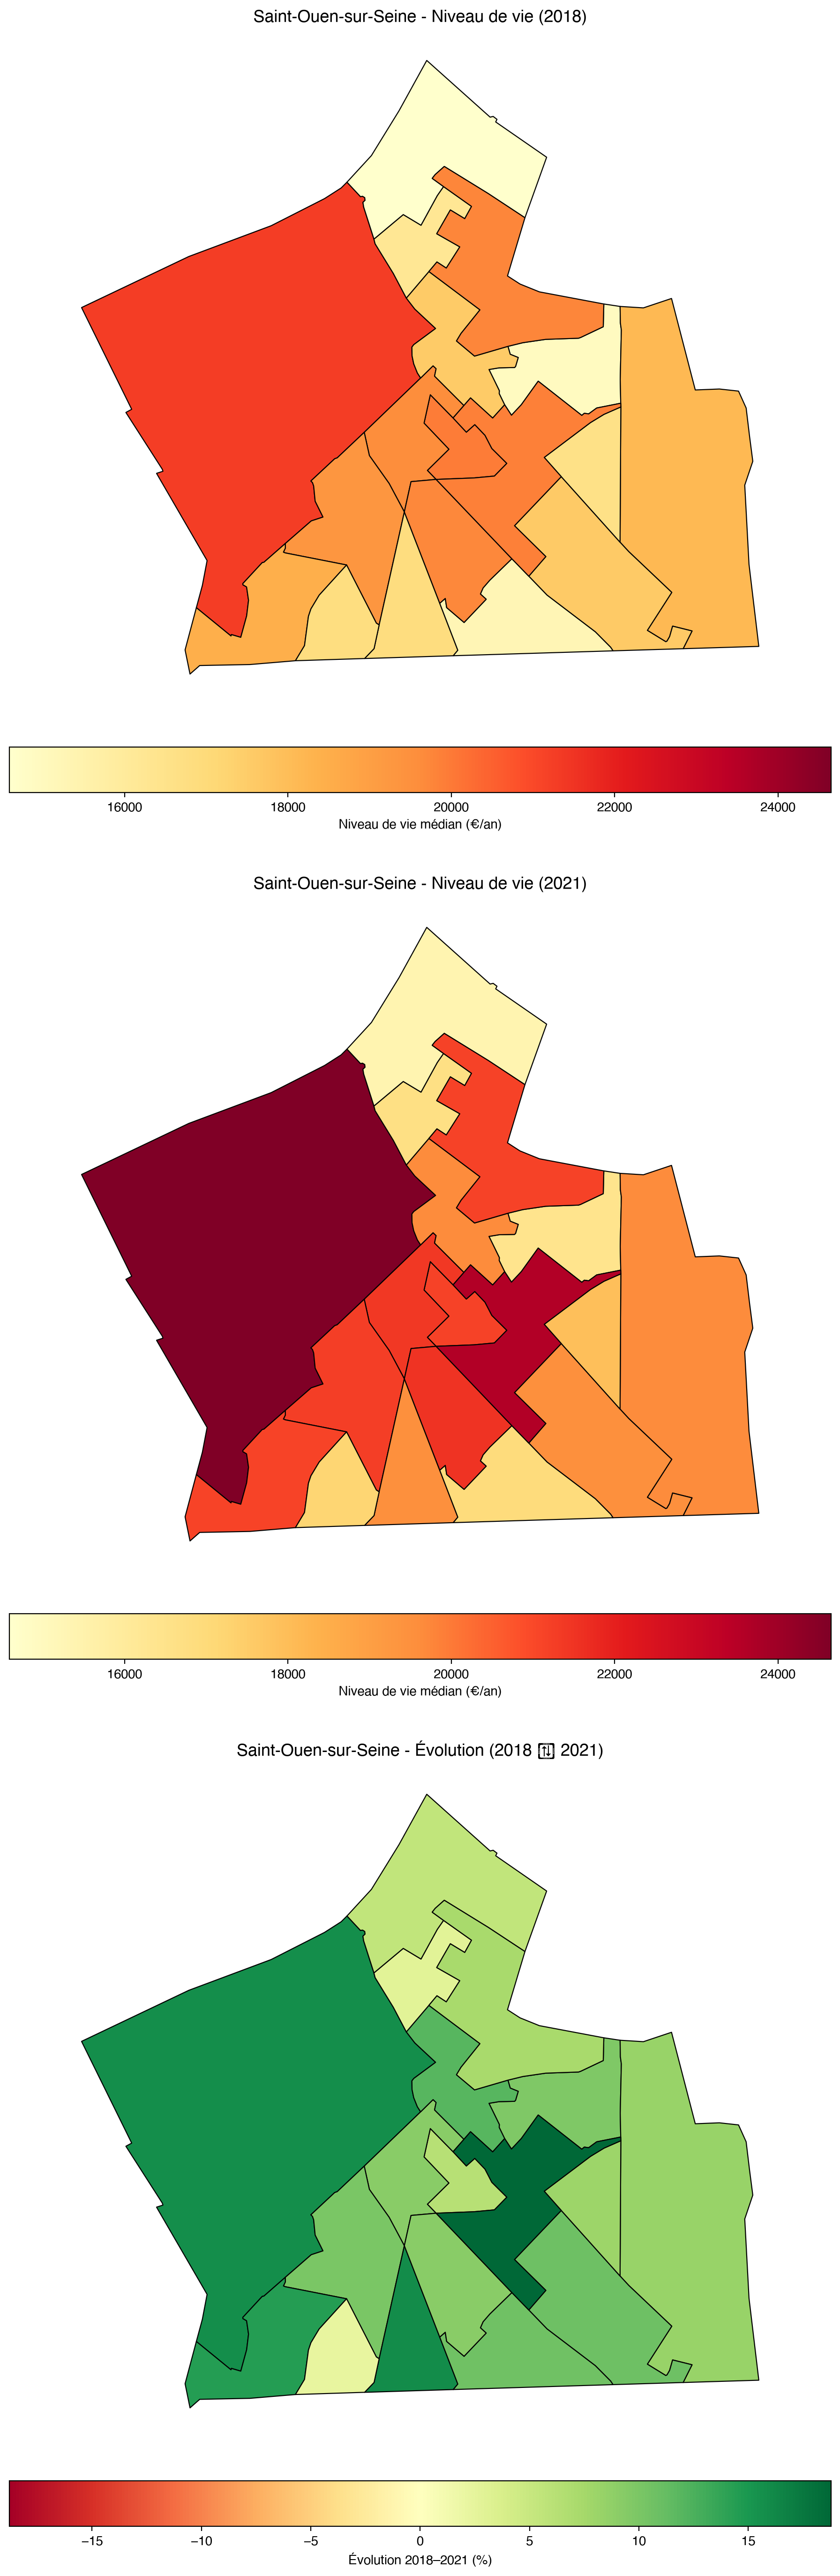

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(10, 28))

options_niv = {
    "cmap": "YlOrRd",
    "vmin": vmin_niv,
    "vmax": vmax_niv,
    "edgecolor": "black",
    "linewidth": 0.8,
    "legend": True,
    "missing_kwds": {"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    "legend_kwds": {
        "label": "Niveau de vie médian (€/an)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
}

st_ouen_2018.plot(ax=axes[0], column=col_niv_2018, **options_niv)
axes[0].set_title("Saint-Ouen-sur-Seine - Niveau de vie (2018)", fontsize=13)
utils.cadrer_carte(axes[0], st_ouen_2018)

st_ouen_2021.plot(ax=axes[1], column=col_niv_2021, **options_niv)
axes[1].set_title("Saint-Ouen-sur-Seine - Niveau de vie (2021)", fontsize=13)
utils.cadrer_carte(axes[1], st_ouen_2021)

st_ouen_evol.plot(
    ax=axes[2],
    column="evol_pct",
    cmap="RdYlGn",
    norm=norm_evol,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Évolution 2018–2021 (%)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[2].set_title(
    "Saint-Ouen-sur-Seine - Évolution (2018 → 2021)", fontsize=13
)
utils.cadrer_carte(axes[2], st_ouen_evol)

plt.tight_layout()
plt.show()

On remarque une hausse généralisée des niveaux de vie entre 2018 et 2021. La carte d'évolution montre une progression sur l'ensemble des IRIS de Saint-Ouen (environ +3 % à +18 %, sans recul marqué), ce qui traduit un enrichissement global ou une évolution favorable du revenu médian sur la période entourant l'arrivée de la ligne 14.   
Il y a aussi une accentuation des écarts entre quartiers. Alors que les IRIS au nord et au sud partent de niveaux plus modestes en 2018 (15 000–16 000 €/an) et progressent plus modérément, le grand secteur à l'ouest et un secteur central est affichent à la fois les plus fortes hausses relatives et les niveaux les plus élevés en 2021 (jusqu'à 24 000 €/an et plus). Cette hausse plus rapide dans certains quartiers est cohérente avec une dynamique de gentrification sélective plutôt qu'uniforme, mais elle ne suffit pas à la prouver seule.   

### B- Mixité sociale et part des cadres à Saint-Ouen : une transformation inégale selon les quartiers

On cartographie maintenant l'évolution de la composition sociale des IRIS de Saint-Ouen entre 2011 et 2022, à travers deux indicateurs : la part des cadres et l'indice de mixité sociale (Shannon). Comme pour le niveau de vie, on s'intéresse aux variations plutôt qu'aux niveaux absolus.

/Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/.venv/lib/python3.14/site-packages/geopandas/plotting.py:1339: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  ax.figure.canvas.draw_idle()
/var/folders/0w/czcrdq993f90fd70tsy9vw580000gn/T/ipykernel_97066/2162110199.py:16: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  plt.tight_layout()
/Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from font(s) Helvetica.
  fig.canvas.print_figure(bytes_io, **kw)


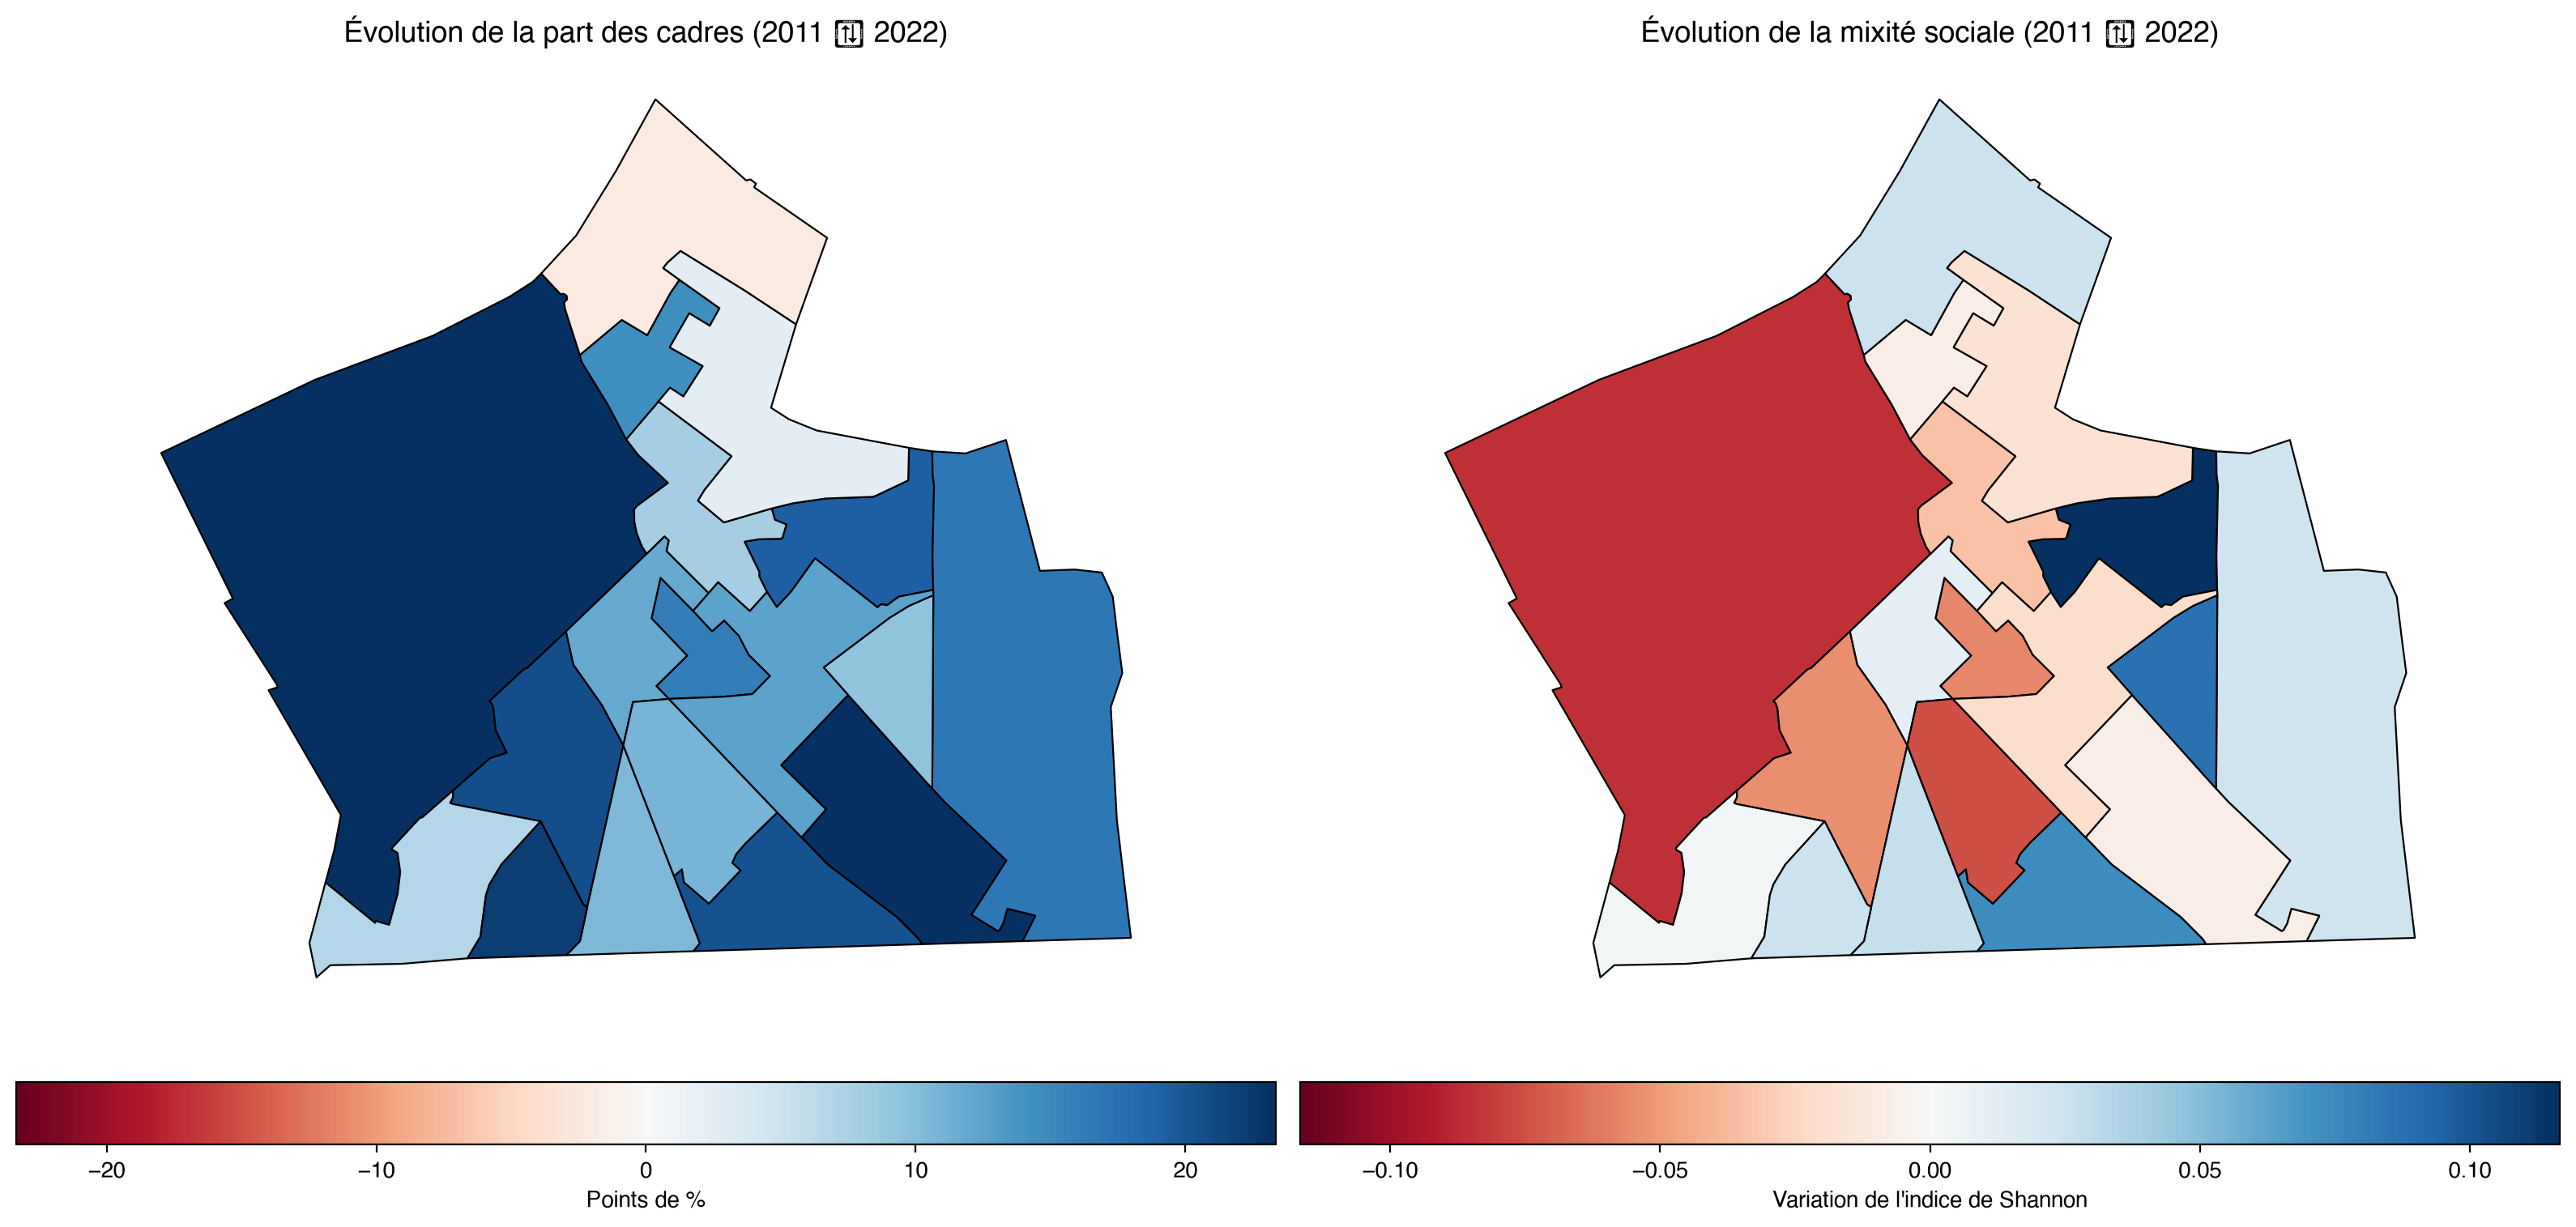

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, col, titre, label in [
    (axes[0], "d_cadres", "Évolution de la part des cadres (2011 → 2022)", "Points de %"),
    (axes[1], "d_mixite", "Évolution de la mixité sociale (2011 → 2022)", "Variation de l'indice de Shannon"),
]:
    lim = evol[col].abs().max()
    evol.plot(
        ax=ax, column=col, cmap="RdBu", norm=TwoSlopeNorm(0, -lim, lim),
        edgecolor="black", linewidth=0.8, legend=True,
        missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
        legend_kwds={"label": label, "orientation": "horizontal", "pad": 0.05},
    )
    ax.set_title(titre, fontsize=13)
    utils.cadrer_carte(ax, evol)

plt.tight_layout()
plt.show()

La quasi totalité des IRIS de Saint-Ouen voit sa part de cadres augmenter entre 2011 et 2022. Presque toute la carte est dans les bleus, avec des hausses qui atteignent environ 20 points.
Les plus fortes hausses se concentrent dans le grand IRIS de l'ouest et dans plusieurs IRIS du sud et de l'est. Le reste de l'est de la commune connaît une hausse plus modérée, de l'ordre de 10 à 15 points.
Seuls quelques IRIS du nord restent proches de zéro, avec une très légère baisse pour l'un d'eux. La montée en gamme sociale concerne donc l'ensemble de la commune, mais de façon très inégale.

Du point de vue de la mixité sociale, le tableau est plus contrasté. Les variations vont d'environ 0,10 de baisse à 0,10 de hausse, et les IRIS se répartissent entre hausses et baisses.
La mixité diminue fortement dans le grand IRIS de l'ouest et dans plusieurs IRIS du centre et du sud. Elle augmente dans l'IRIS situé à l'est du centre, qui connaît la plus forte hausse, ainsi que dans le sud et sur la frange nord et est.

Ce qu'on peut conclure, c'est que ces deux indicateurs ne vont pas de pair. Dans l'IRIS de l'ouest, la part des cadres progresse beaucoup alors que la mixité recule. Cela traduit une composition qui s'homogénéise autour d'un groupe devenu dominant, plutôt qu'un enrichissement de la diversité sociale. À l'inverse, dans l'IRIS de l'est du centre, la mixité augmente en même temps que la part des cadres. L'arrivée de cadres y rééquilibre une composition auparavant plus homogène. Dans le nord, la part des cadres est stable et la mixité progresse légèrement : ces IRIS se transforment moins que le reste de la commune.

Cependant, il est important de noter que ces cartes décrivent des changements et non des relations de cause à effet. Plusieurs dynamiques ont pu jouer en parallèle, comme la construction de logements neufs ou la valorisation de certains quartiers. Enfin, une évolution forte dans un grand IRIS peut également venir de programmes de construction qui changent la population résidente, et non d'une transformation des mêmes habitants.

### C- Une structure des ménages qui évolue

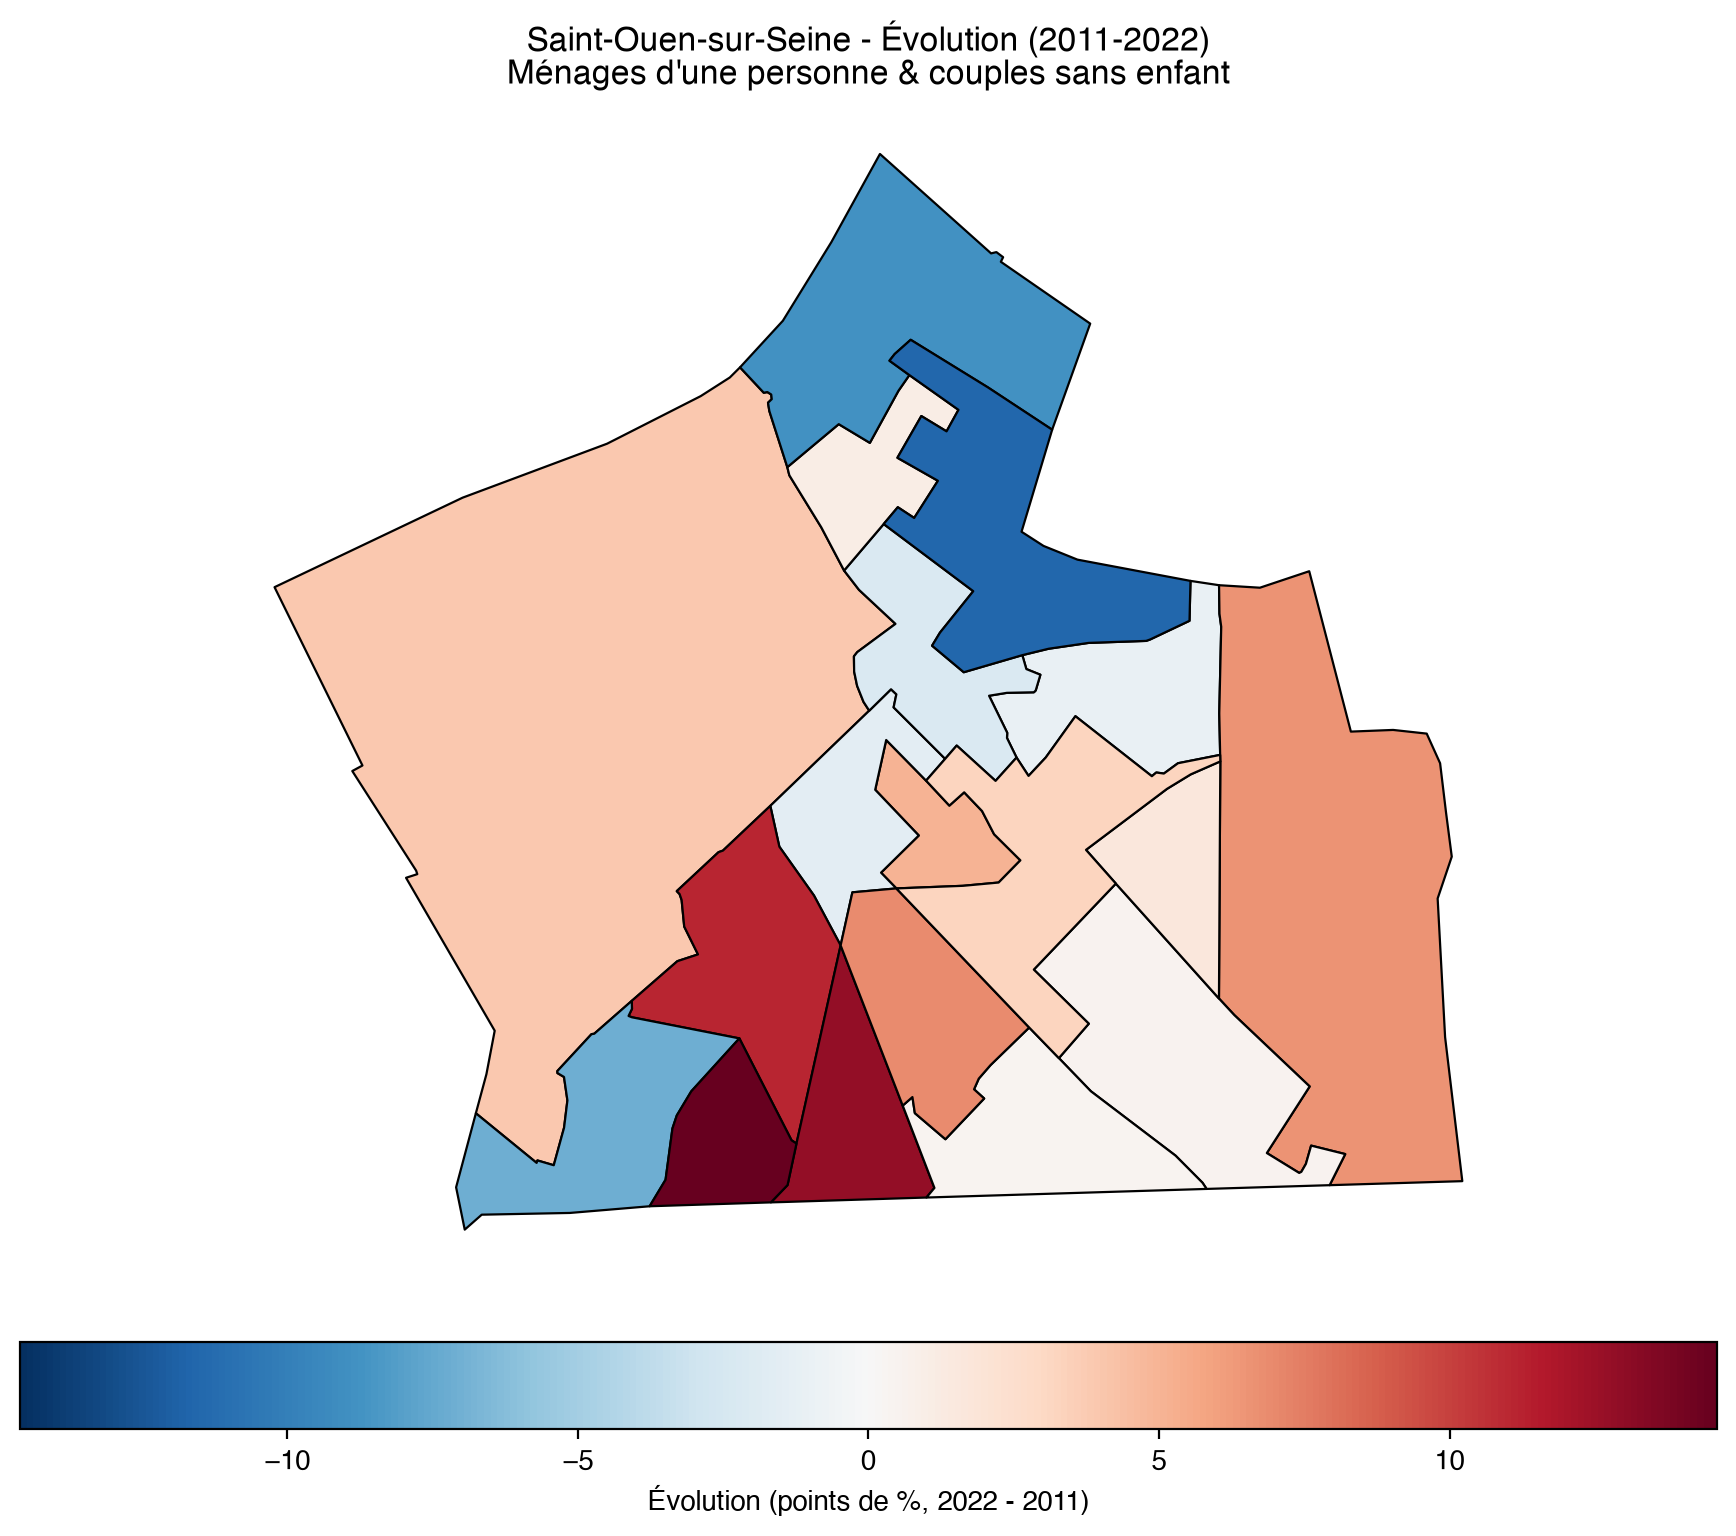

In [22]:
utils.tracer_carte_evolution(
    evol_menages, 2011, 2022,
    titre="Ménages d'une personne & couples sans enfant",
)

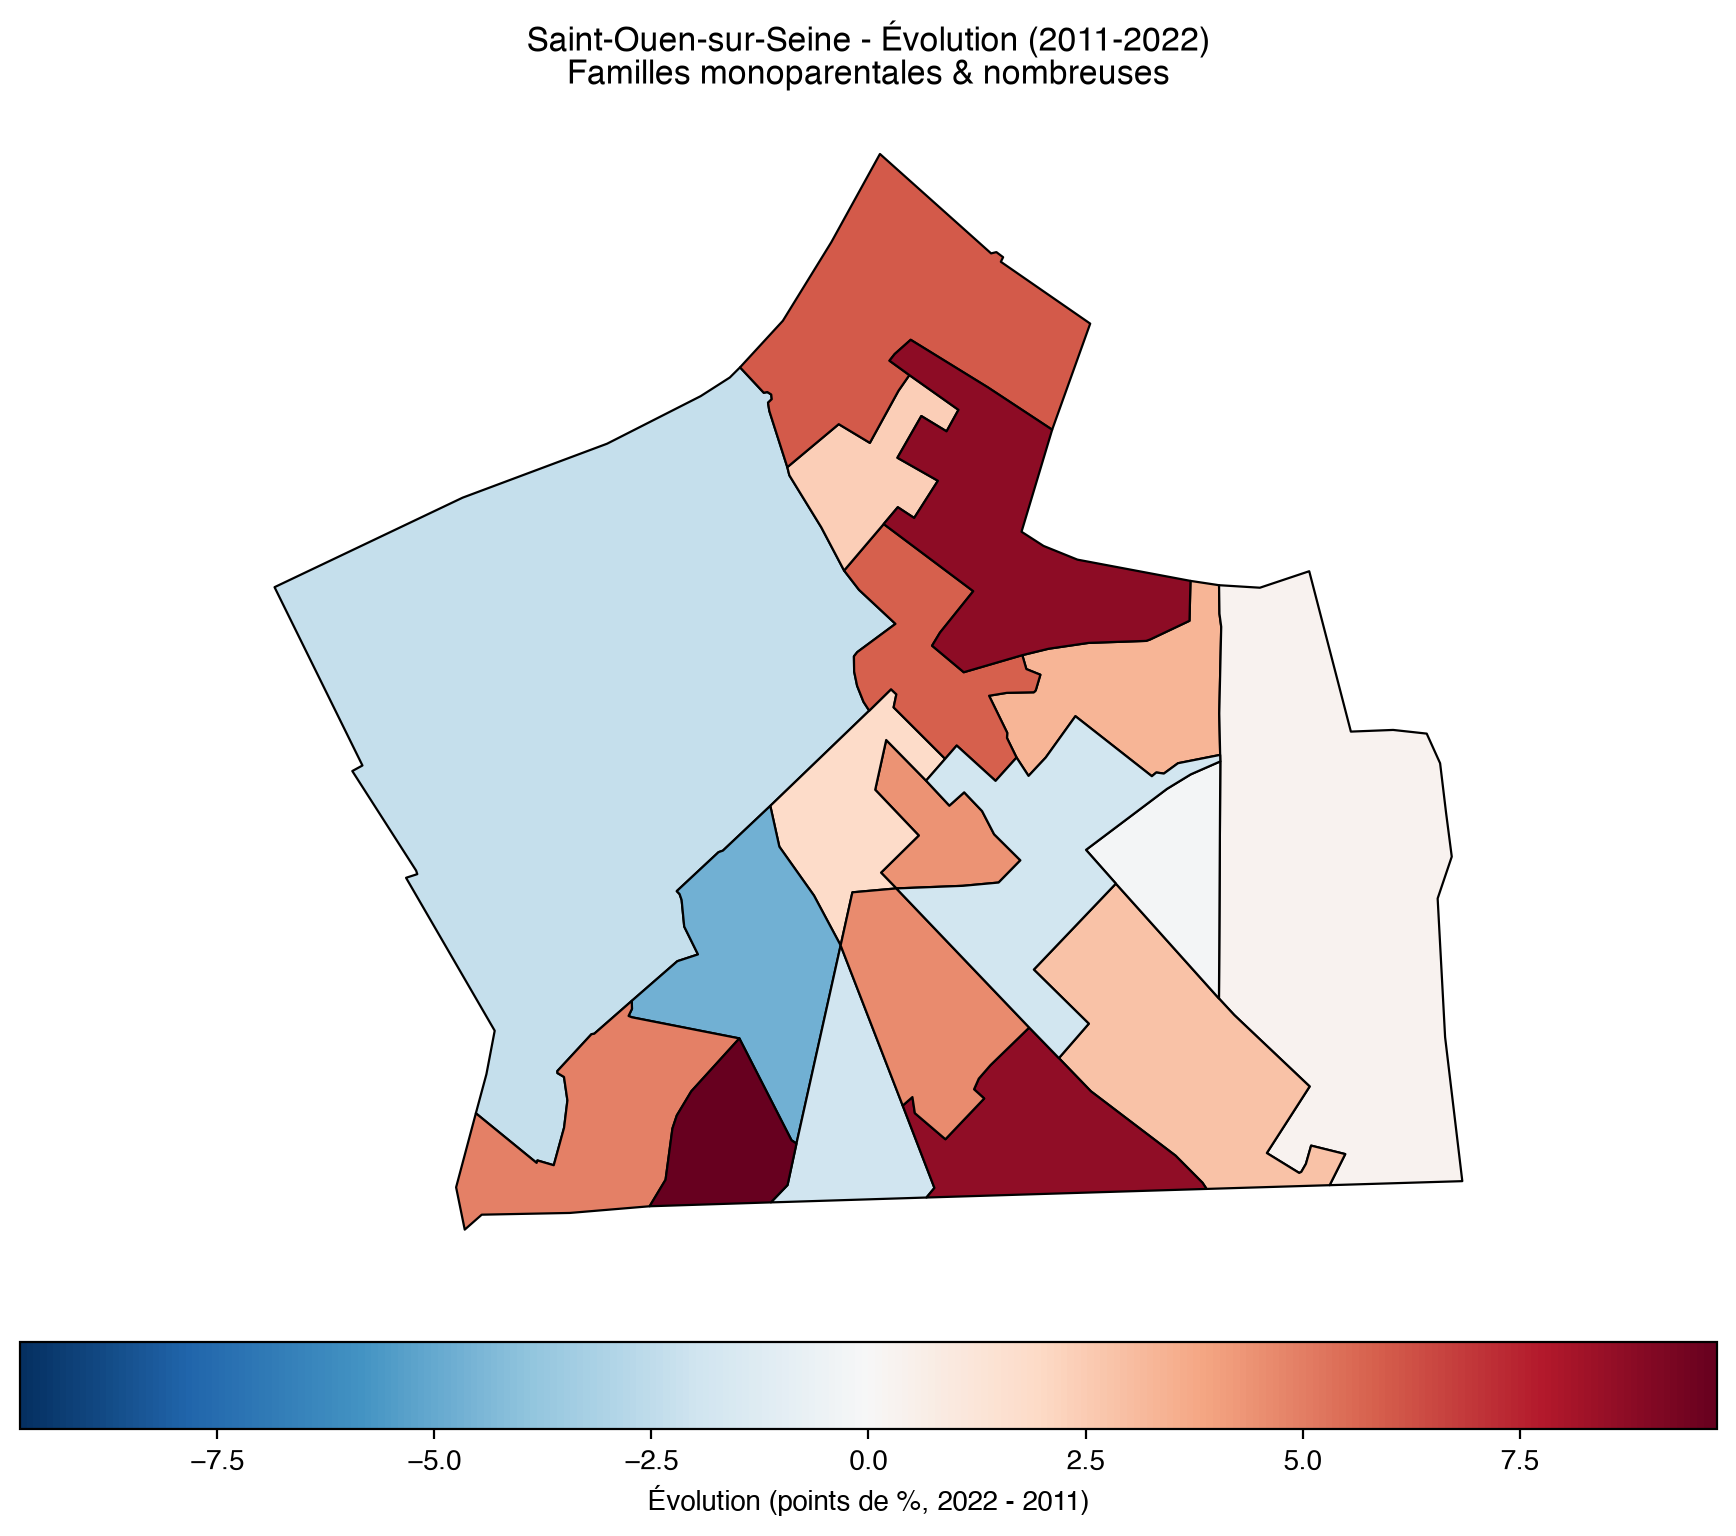

In [23]:
utils.tracer_carte_evolution(
    evol_familles, 2011, 2022,
    titre="Familles monoparentales & nombreuses",
)

Les deux cartes sont lues en points de pourcentage, avec la même convention de couleurs : le rouge indique une hausse de la part de l'indicateur entre 2011 et 2022, le bleu une baisse. Les échelles diffèrent (environ ±14 points pour la première carte, ±9 points pour la seconde), donc une même nuance ne représente pas la même variation d'une carte à l'autre.

**Ménages d'une personne et couples sans enfant**

- La part de ces ménages augmente dans la majorité de la commune, en particulier dans le grand IRIS de l'ouest (environ +3 à +4 points) et dans l'IRIS de l'est (environ +6 points).
- Les hausses les plus fortes se concentrent dans le sud, avec plusieurs IRIS entre +10 et +14 points.
- Le nord fait exception : la part de ces ménages recule nettement, de l'ordre de −7 points pour l'IRIS situé au nord et d'environ −10 points pour celui du nord du centre. Le sud-ouest compte aussi un IRIS en baisse (environ −5 points).
- Le centre de la commune varie peu, avec des IRIS proches de zéro.

**Familles monoparentales et nombreuses**

- Le profil est presque inverse. La part de ces familles augmente fortement dans le nord et le nord du centre (de +6 à +9 points) ainsi que dans le sud-ouest et le sud-est, avec des hausses qui atteignent environ +9 points.
- Elle diminue dans le grand IRIS de l'ouest (environ −2 à −3 points) et dans un IRIS du sud-ouest du centre (environ −4 points).
- L'est de la commune reste stable, avec une variation proche de zéro.

**Croisement des deux cartes**

- Dans le nord, les deux cartes se répondent : les ménages sans enfant reculent pendant que les familles monoparentales et nombreuses progressent. Ces quartiers évoluent vers un profil plus familial.
- Dans plusieurs IRIS du sud, du sud-ouest du centre et dans le grand IRIS de l'ouest, c'est l'inverse : les ménages d'une personne et les couples sans enfant gagnent du terrain, et la part des familles baisse ou stagne.
- L'est cumule une hausse nette des petits ménages et une stabilité des familles, ce qui indique un profil qui se rapproche de celui des IRIS du sud sans les mêmes mouvements de familles.
- Un IRIS du sud-ouest fait exception : les deux parts augmentent fortement. Les deux indicateurs ne sont pas complémentaires, car ils sont rapportés à l'ensemble des ménages et d'autres types de ménages (comme les couples avec enfants) ne figurent dans aucun des deux. Dans cet IRIS, ces autres ménages ont donc probablement reculé.

## IV - Logements et transactions : comment évolue le cadre résidentiel ?

L’analyse menée dans la section A met en évidence un essor marqué des projets de construction à partir de 2015. Ce calendrier coïncide avec le début des travaux de la ligne 14 en juin 2014, ce qui conduit à examiner dans quelle mesure l’arrivée de cette infrastructure est associée à une revalorisation des prix immobiliers.

Pour cela on commence donc par charger les stations proches de notre zone d'étude, en l'ocurrence ici la commune de Saint-Ouen :

In [24]:
stations_proches = utils.charger_stations_proches(zone_etude)

On compare ensuite les mutations immobilières selon leur proximité réelle avec une station de métro.

On écarte d’abord les mutations sans coordonnées (année ou prix au m²) puis projette les points des ventes et les stations en EPSG:2154 afin de calculer des distances en mètres. Chaque mutation est affectée à la station la plus proche et classée dans l’un des deux groupes : à moins de 500 m ou à 500 m et plus. 

Enfin, on calcule, pour chaque année et chaque groupe, le prix médian au m² et le nombre de mutations, puis affiche ces deux tableaux. 

In [25]:
DISTANCE_SEUIL_M = 500

df_analyse = df_logements.dropna(
    subset=["longitude", "latitude", "annee", "prix_m2"]
).copy()

ventes_geo = gpd.GeoDataFrame(
    df_analyse,
    geometry=gpd.points_from_xy(df_analyse["longitude"], df_analyse["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:2154")

stations_geo = stations_proches.to_crs("EPSG:2154")

df_analyse["dist_station_m"] = ventes_geo.geometry.apply(
    lambda point: stations_geo.geometry.distance(point).min()
).to_numpy()

groupe_proche = "Zone Traitée (< 500m)"
groupe_eloigne = "Zone Contrôle (≥ 500m)"

df_analyse["groupe"] = groupe_eloigne
df_analyse.loc[df_analyse["dist_station_m"] < DISTANCE_SEUIL_M, "groupe"] = groupe_proche

ordre_groupes = [groupe_proche, groupe_eloigne]

table_prix = (
    df_analyse.groupby(["annee", "groupe"])["prix_m2"]
    .median()
    .unstack()
    .reindex(columns=ordre_groupes)
)

table_effectifs = (
    df_analyse.groupby(["annee", "groupe"])["prix_m2"]
    .count()
    .unstack()
    .reindex(columns=ordre_groupes)
)

print("Prix médian au m² (€) par proximité réelle d'une station")
display(table_prix.round(0))

print("Nombre de mutations par année et groupe")
display(table_effectifs)

Prix médian au m² (€) par proximité réelle d'une station


groupe,Zone Traitée (< 500m),Zone Contrôle (≥ 500m)
annee,,
2018,5276.0,5278.0
2019,6000.0,5742.0
2020,6221.0,6265.0
2021,6857.0,6654.0
2022,7004.0,6897.0
2023,6767.0,6655.0
2024,6384.0,6220.0
2025,6500.0,6349.0


Nombre de mutations par année et groupe


groupe,Zone Traitée (< 500m),Zone Contrôle (≥ 500m)
annee,,
2018,222,503
2019,398,424
2020,329,447
2021,393,556
2022,356,561
2023,264,383
2024,226,352
2025,260,466


On appelle ensuite `calculer_zones_tampons` pour mesurer la proximité des IRIS de la zone d’étude par rapport aux stations.

La fonction projette les IRIS et les stations en Lambert-93 (`EPSG:2154`), un système adapté aux calculs de distances en mètres. Pour chaque IRIS, elle mesure la distance entre son centroïde et la station la plus proche, puis le classe en zone traitée ou zone de contrôle selon le seuil indiqué par `DISTANCE_SEUIL_M`.

Elle construit également deux zones tampons autour des stations : `buffer_traite`, au rayon du seuil choisi (500 m ici), et `buffer_etendu`, au rayon par défaut de 800 m. Les trois résultats sont renvoyés dans le système de coordonnées d’origine.

- `iris_classes` contient les IRIS, leur distance à la station la plus proche et leur groupe.
- `buffer_traite` et `buffer_etendu` sont les zones tampons, utiles notamment pour les visualisations cartographiques.

**Attention :** la distance est calculée depuis le centroïde de chaque IRIS, pas depuis chaque logement vendu. De plus, la condition du code classe une distance exactement égale au seuil comme « traitée » (`<=`), même si l’étiquette affiche « < 500 m ».

In [26]:
iris_classes, buffer_traite, buffer_etendu = utils.calculer_zones_tampons(
    zone_etude,
    stations_proches,
    dist_traitee=DISTANCE_SEUIL_M,
)

On définit puis exécute ensuite la fonction `analyser_evolution_prix_par_distance`. Elle vérifie la présence des colonnes nécessaires, associe chaque vente à son IRIS et au groupe de proximité de cet IRIS, puis écarte les ventes dont l’année ou le prix au m² est manquant. Elle calcule ensuite, pour chaque année et chaque groupe, le prix médian au m² et le nombre de ventes.

Les groupes sont attribués aux IRIS selon leur distance aux stations; les ventes héritent donc du groupe de leur IRIS. La fonction renvoie les données associées et les deux tableaux récapitulatifs.

In [27]:
def analyser_evolution_prix_par_distance(df_ventes, iris_classes):
    """Calcule médianes et effectifs annuels par groupe de distance."""
    colonnes_requises = {utils.COL_IRIS, "annee", "prix_m2"}
    colonnes_absentes = colonnes_requises - set(df_ventes.columns)
    if colonnes_absentes:
        raise ValueError(
            f"Colonnes de ventes absentes pour l'analyse : {sorted(colonnes_absentes)}"
        )

    groupes_iris = iris_classes[
        [utils.COL_IRIS, "groupe", "dist_station_m"]
    ].copy()
    ventes = df_ventes.copy()
    ventes[utils.COL_IRIS] = ventes[utils.COL_IRIS].astype("string")
    groupes_iris[utils.COL_IRIS] = groupes_iris[utils.COL_IRIS].astype("string")
    df_analyse = ventes.merge(
        groupes_iris,
        on=utils.COL_IRIS,
        how="inner",
        validate="many_to_one",
    ).dropna(subset=["annee", "prix_m2"])
    if df_analyse.empty:
        raise ValueError("Aucune vente exploitable n'est associée à un IRIS classé.")

    table_prix = (
        df_analyse.groupby(["annee", "groupe"])["prix_m2"]
        .median()
        .unstack()
    )
    table_effectifs = (
        df_analyse.groupby(["annee", "groupe"])["prix_m2"]
        .count()
        .unstack()
    )
    return df_analyse, table_prix, table_effectifs


df_analyse, table_prix, table_effectifs = analyser_evolution_prix_par_distance(
    df_logements,
    iris_classes,
)

La seconde cellule trace l’évolution annuelle du prix médian au m² pour chaque groupe. Les couleurs et les marqueurs distinguent les groupes, tandis que la ligne verticale pointillée situe la mise en service de la ligne 14 en décembre 2020. La mise en forme de l’axe des prix, la grille et la légende facilitent la lecture du graphique.

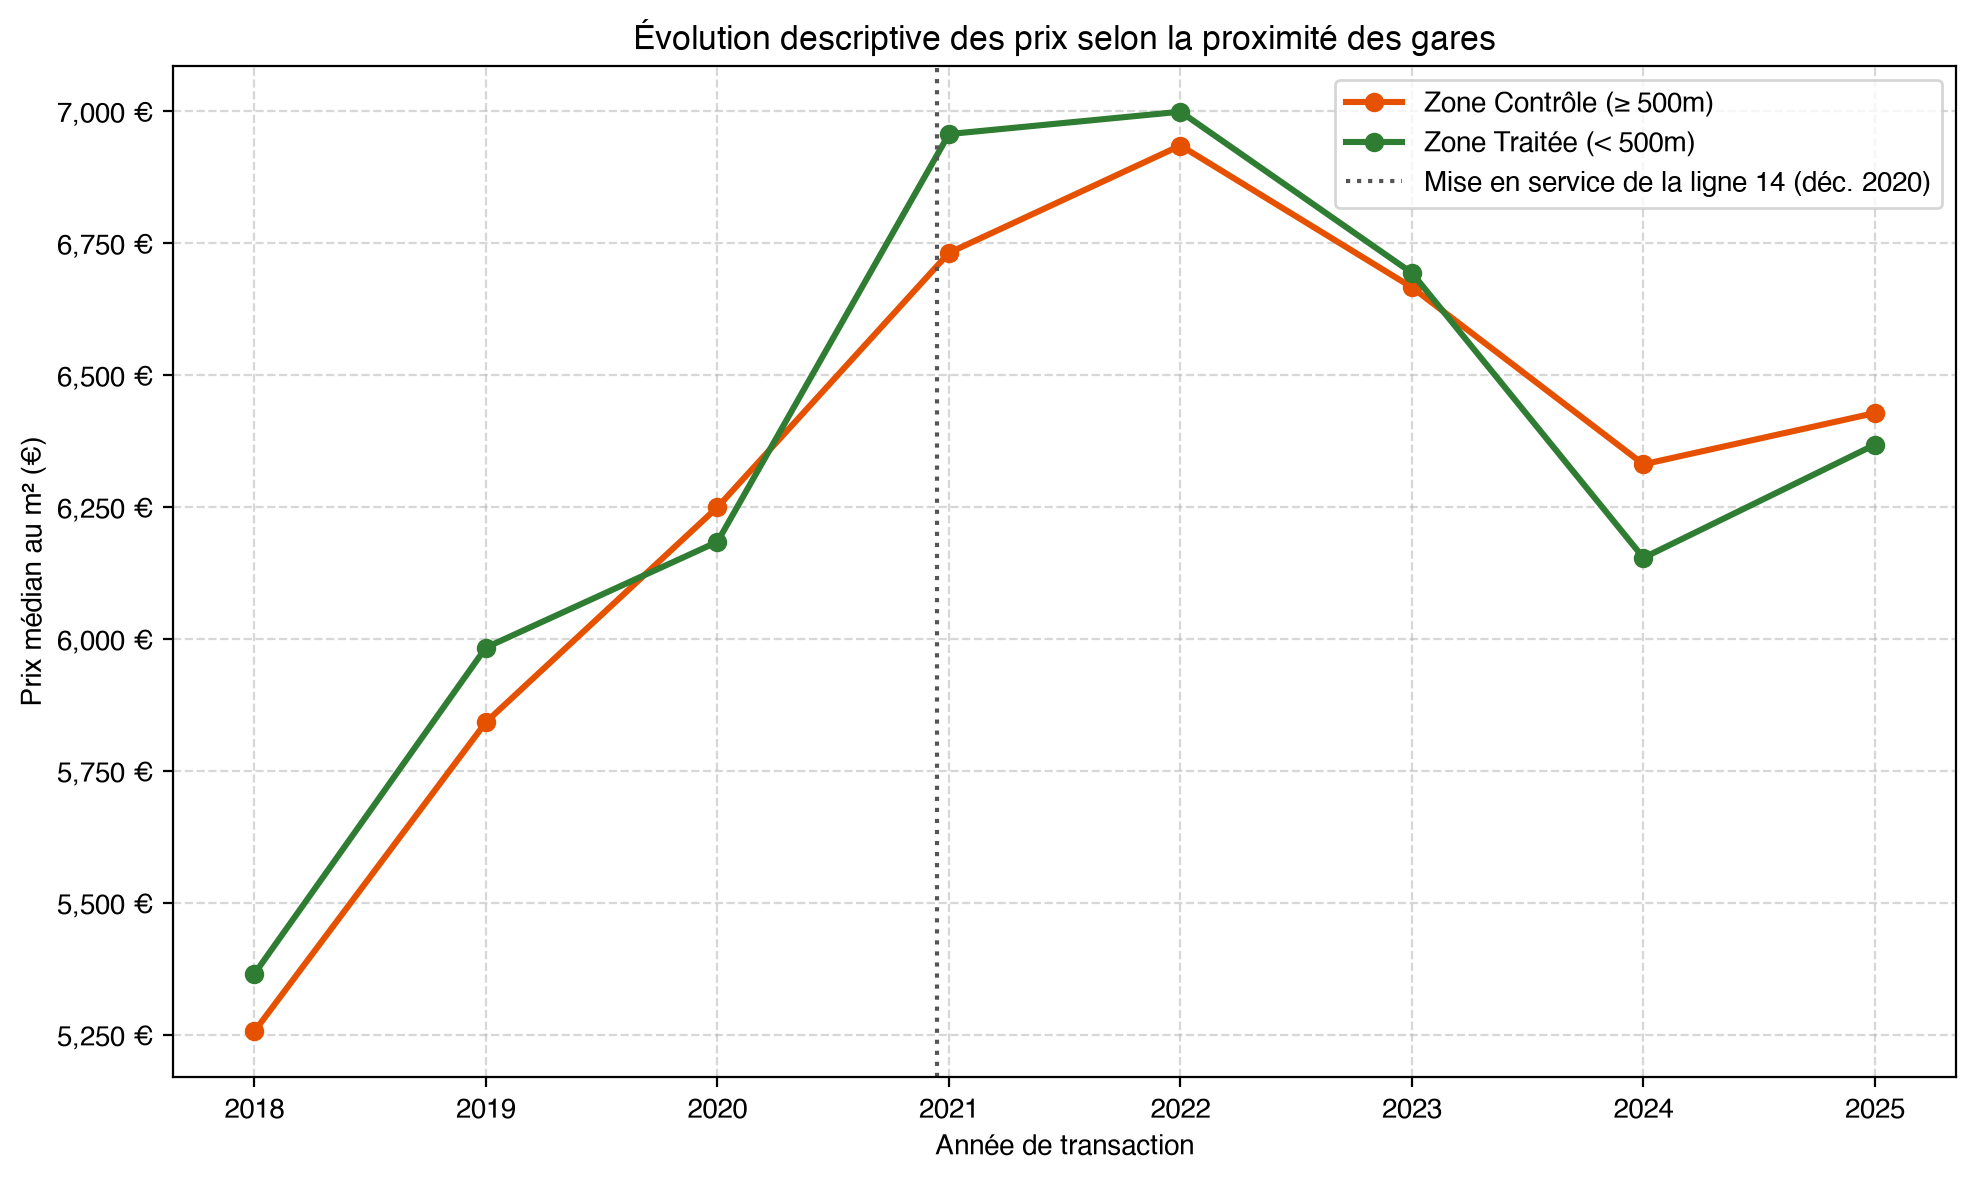

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))
couleurs = ["#e65100", "#2e7d32"]

for couleur, groupe in zip(couleurs, table_prix.columns):
    ax.plot(
        table_prix.index,
        table_prix[groupe],
        marker="o",
        linewidth=2.2,
        color=couleur,
        label=groupe,
    )

ax.axvline(
    x=2020.95,
    color="#555555",
    linestyle=":",
    linewidth=1.5,
    label="Mise en service de la ligne 14 (déc. 2020)",
)
ax.set_title("Évolution descriptive des prix selon la proximité des gares")
ax.set_xlabel("Année de transaction")
ax.set_ylabel("Prix médian au m² (€)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f} €"))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()


En 2018, les prix médians au m² sont presque identiques dans les deux zones : 5 276 € à moins de 500 mètres d’une station, contre 5 278 € au-delà. Les prix augmentent ensuite dans les deux groupes jusqu’en 2022, où ils atteignent leur niveau le plus élevé : 7 004 € dans la zone proche et 6 897 € dans la zone de contrôle. Ils baissent ensuite jusqu’en 2024, avant de remonter légèrement en 2025.

À partir de 2021, le prix médian est chaque année plus élevé dans la zone proche des stations. L’écart reste toutefois modéré : entre 107 € et 203 €/m², soit environ 1,6 % à 3,1 % par rapport à la zone de contrôle. Les évolutions des deux groupes restent globalement similaires.

Ces résultats sont descriptifs et ne suffisent pas à conclure que la proximité d’une station entraîne une hausse des prix ou révèle, à elle seule, un phénomène de gentrification. Les effectifs de ventes diffèrent entre les groupes et varient selon les années — de 222 à 398 mutations dans la zone proche, contre 352 à 561 dans la zone de contrôle. Les différences observées peuvent aussi refléter la composition des logements vendus ou les caractéristiques des quartiers. Une analyse causale nécessiterait notamment de contrôler ces facteurs et de comparer les évolutions avant et après la mise en service des stations.

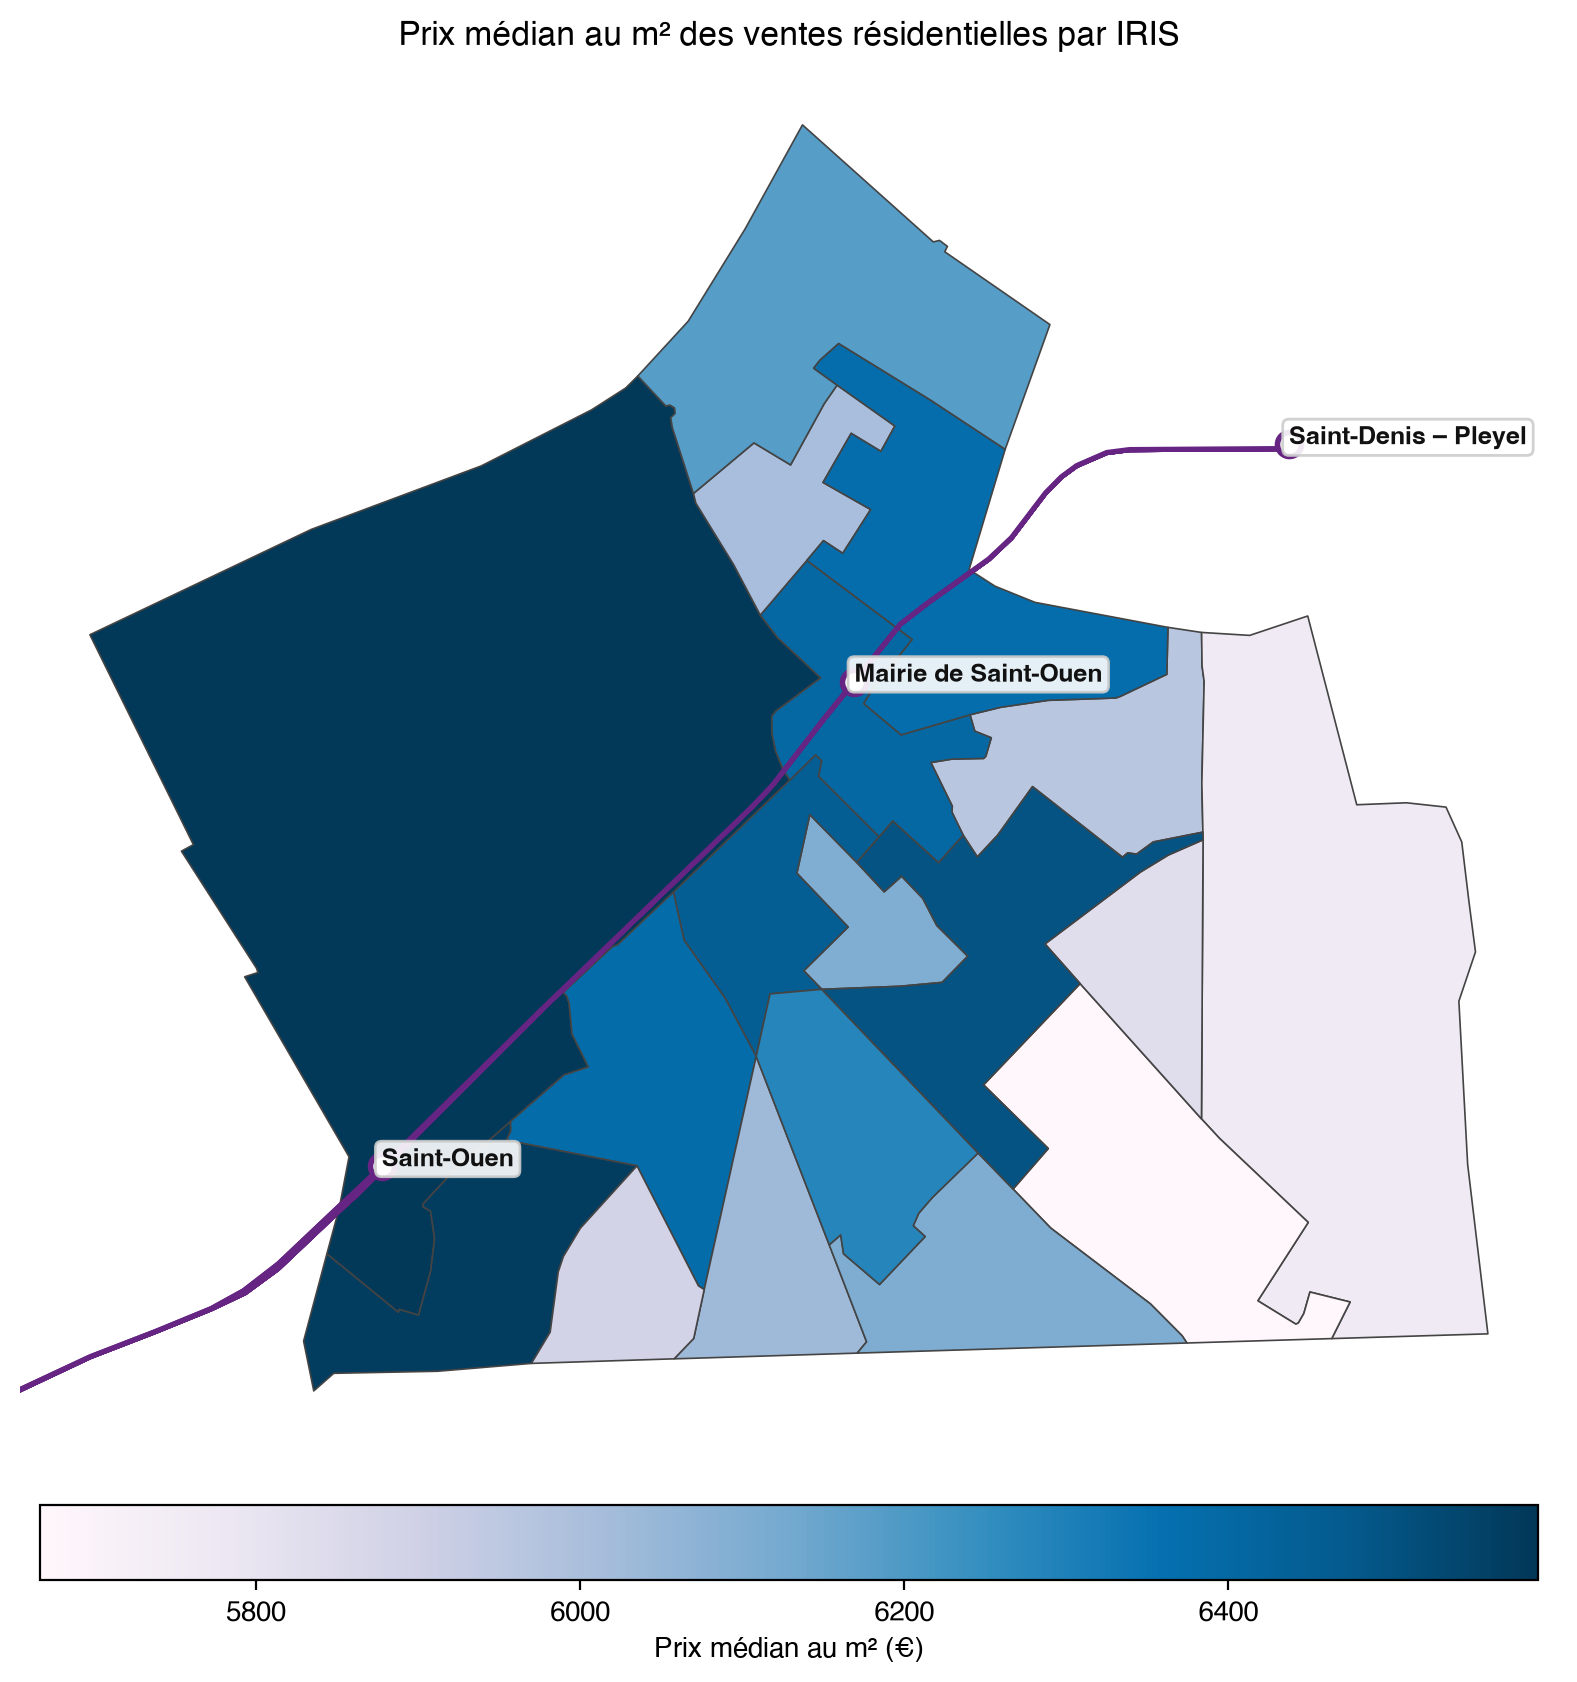

In [30]:
traces_transport = utils.charger_ligne_14(zone_etude)

zone_etude_dvf = utils.agreger_dvf_par_iris(df_logements, zone_etude)

fig, ax = plt.subplots(figsize=(11, 9))

zone_etude_dvf.plot(
    column="prix_m2_median",
    cmap="PuBu",
    linewidth=0.6,
    edgecolor="#444444",
    legend=True,
    legend_kwds={
        "label": "Prix médian au m² (€)",
        "orientation": "horizontal",
        "shrink": 0.7,
        "pad": 0.03,
    },
    missing_kwds={"color": "#e0e0e0", "label": "Aucune vente géolocalisée"},
    ax=ax,
)
traces_transport.plot(ax=ax, color="#662483", linewidth=1.5, zorder=3)
stations_proches.plot(
    ax=ax,
    color="white",
    edgecolor="#662483",
    linewidth=2.0,
    markersize=75,
    zorder=4,
)
utils.etiqueter_stations(ax, stations_proches, fontsize=9)
utils.cadrer_carte(ax, zone_etude)
ax.set_title("Prix médian au m² des ventes résidentielles par IRIS")
plt.tight_layout()
plt.show()

La carte présente le prix médian au m² des ventes résidentielles par IRIS à Saint-Ouen-sur-Seine, obtenu par agrégation des données DVF et jointure spatiale des mutations géolocalisées sur les contours IRIS, avec le tracé de la ligne 14 et ses trois gares de la commune (Saint-Ouen, Mairie de Saint-Ouen, Saint-Denis – Pleyel). Les prix s'échelonnent d'environ 5 700 €/m² dans les IRIS les moins chers à plus de 6 500 €/m² dans les plus chers, soit une amplitude d'environ 800 €/m² entre quartiers.

La lecture la plus frappante est le contraste est–ouest. Les IRIS situés à l'ouest de la commune, autour de la gare de Saint-Ouen et le long des limites avec Clichy et Paris (18e arrondissement), affichent les valeurs les plus élevées de la carte, avec un large IRIS dépassant visiblement 6 500 €/m². Cet écart s'explique par plusieurs facteurs complémentaires. D'une part, ces quartiers ouest sont les plus anciens et les plus denses de la ville : le secteur de la gare de Saint-Ouen et le vieux village forment un tissu haussmannien et faubourien recherché, à deux pas du 18e arrondissement où les prix au m² dépassent largement 8 000 €/m². La proximité immédiate de Paris produit un effet de report de la demande : une partie des ménages contraints budgétairement à Paris se porte sur la frange audonienne, ce qui tire les prix vers le haut. D'autre part, ces IRIS sont très bien desservis : la gare de Saint-Ouen (ligne 13 et RER C à proximité) précède l'arrivée de la ligne 14, et la zone se trouve au cœur du grand projet de renouvellement urbain des Docks de Saint-Ouen, anticipé par les acheteurs.

À l'inverse, les IRIS de l'est de la commune, du côté de Saint-Denis – Pleyel, affichent les valeurs les plus faibles, autour de 5 700 à 5 900 €/m². Ces secteurs, longtemps marqués par une dominante industrielle et des grands ensembles de logements sociaux, bénéficient de la ligne 14 depuis fin 2024 seulement. Le nouveau tracé y fait mécaniquement monter la demande (l'effet traitement de l'ouverture de gare), mais l'ajustement des prix est progressif : la médiane observée reflète encore un parc immobilier et une structure résidentielle différents de ceux des quartiers ouest. On notera également qu'un des IRIS centraux, autour de la Mairie de Saint-Ouen, affiche une valeur intermédiaire inférieure à 6 000 €/m², plus faible que ses voisins immédiats : ce type d'anomalie locale peut traduire soit un parc spécifique (petits logements, copropriétés dégradées), soit surtout un faible nombre de ventes sur la période, qui rend la médiane sensible à quelques mutations atypiques.

Une réserve méthodologique doit enfin être signalée. Le prix au m² est un proxy calculé à l'échelle de la mutation : la valeur foncière totale est divisée par la seule surface résidentielle, ce qui peut inclure une dépendance vendue dans la même mutation. Par ailleurs, la médiane par IRIS repose sur un nombre de ventes parfois réduit, et les IRIS sans vente géolocalisée ne peuvent être colorés. Ces valeurs doivent donc être lues comme des ordres de grandeur comparatifs entre quartiers plutôt que comme des prix exhaustifs du marché audonien.

## Conclusion

Ce travail visait à savoir dans quelle mesure Saint-Ouen connaît une recomposition socio-spatiale depuis les années 2010, et comment elle varie d'un quartier à l'autre. À l'échelle des IRIS, les données publiques mobilisées montrent une commune qui change sur plusieurs dimensions à la fois, mais dont les quartiers ne suivent pas la même trajectoire.

Sur le plan démographique, la population s'élargit surtout dans les classes d'âge actif entre 2012 et 2023, en particulier chez les 25 à 39 ans, tandis que la base de la pyramide reste stable. Sur le plan socio-économique, le niveau de vie médian progresse dans tous les IRIS entre 2018 et 2021, mais plus vite dans certains quartiers, notamment à l'ouest et dans un secteur du centre-est. La part des cadres augmente dans la quasi-totalité des IRIS entre 2011 et 2022, avec des hausses allant jusqu'à une vingtaine de points. La mixité sociale évolue de façon plus contrastée : elle recule dans le grand IRIS de l'ouest, où la part des cadres progresse le plus, et progresse dans d'autres secteurs. Une montée en gamme sociale ne s'accompagne donc pas toujours d'une plus grande diversité.

La structure des ménages va dans le même sens d'une transformation inégale. Les ménages d'une personne et les couples sans enfant gagnent du terrain dans l'ouest, l'est et surtout le sud, alors qu'ils reculent dans le nord, où la part des familles monoparentales et nombreuses augmente fortement. Sur le marché immobilier, les prix médians au m² sont quasiment identiques en 2018 dans la zone proche des stations et dans la zone de contrôle, atteignent un maximum en 2022, puis baissent jusqu'en 2024. L'écart entre les deux zones reste modéré (environ 2 à 3 %) et les deux courbes évoluent de façon globalement similaire. Au niveau des IRIS, les prix sont plus élevés à l'ouest qu'à l'est.

En croisant ces résultats, l'ouest apparaît comme le secteur où la montée en gamme est la plus marquée : niveaux de vie les plus élevés, hausse forte de la part des cadres, mixité en baisse et prix les plus hauts. Le nord se distingue par un profil plus familial et des évolutions moins marquées des indicateurs socio-économiques. Ces contrastes sont cohérents avec l'idée d'une transformation sélective plutôt qu'uniforme.

Plusieurs limites invitent à la prudence. L'analyse est descriptive : elle mesure des évolutions et des corrélations spatiales, sans identifier de mécanisme causal ni démontrer un phénomène d'éviction résidentielle. Les sources couvrent des périodes différentes (2011 à 2022 pour le recensement, 2018 à 2021 pour Filosofi, 2018 à 2025 pour les transactions), ce qui limite la comparaison directe entre cartes. Les IRIS sont de petite taille et les données du recensement reposent sur un sondage, donc les variations les plus fortes peuvent contenir du bruit. Le prix au m² est un indicateur approximatif, et certains indicateurs regroupent plusieurs types de ménages. Enfin, la construction de logements neufs peut modifier fortement la population d'un grand IRIS sans que les mêmes habitants se soient transformés.

Pour aller plus loin, il faudrait raisonner à population constante, par exemple avec des données individuelles ou de mobilité résidentielle, et contrôler la composition des logements vendus. Une méthode comparant l'évolution avant et après un événement donné, avec des quartiers de contrôle, permettrait aussi de tester des relations de cause à effet.